<a href="https://colab.research.google.com/github/arielsharonferdinandus/Transboundary-Haze-Forecasting/blob/new-data-and-refactor/Transboundary_Haze_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transboundary Haze Forecasting: Predicting PM2.5 Spikes in Singapore
**Theme:** Energy & Environment (Air Quality) | **Type:** Time-Series Forecasting | **Data:** Marine Terrace PM2.5 sensor (9 Apr - 30 Sep 2026) + Marina Barrage daily weather (Jan - Sep 2026)

**Notebook contents**
- **Part 1:** problem formulation, **dataset description**, data-quality audit, cleaning and exploratory analysis (Phases 1-2)
- **Part 2:** feature engineering, forecast targets, leakage tests, chronological train / validation / test split (Phase 3)
- **Part 3:** baselines and candidate models (naive and moving averages, SARIMAX, Holt-Winters, LightGBM, Ridge), evaluated on validation and test (Phase 4), followed by a **Limitations** section
- **Part 4:** hyperparameter tuning of the two shortlisted models with expanding-window cross-validation, default-versus-tuned comparison, final model selection and test evaluation (Phase 5)
- **Part 5:** model interpretation, findings and actionable insights, recommendations, and business implications (Phase 6)

**Headline result:** no tuned model beat a simple 7-day moving average, and no model could forecast the haze spikes (see Parts 4 and 5).

**How to run (Restart runtime, then Run all):** place the data files in a `data/` folder next to the notebook:
- 6 monthly Marine Terrace air-quality files: `openaq_location_6301631_measurments_<month>.csv` (April to September)
- 9 monthly Marina Barrage weather files: `DAILYDATA_S108_<yyyymm>.csv` (January to September)

If the files are not found, the data cell opens an upload dialog on Colab (select all 15 files at once). With the files in `data/`, no manual step is needed.

# Part 1: Problem Formulation, Data Audit and EDA (Phases 1-2)

**Stakeholder:** National Environment Agency (NEA) Singapore / Director of Public Health.

**Predictive question:** Can historical PM2.5 and weather data forecast PM2.5 spikes 24-48 hours ahead during regional haze (Indonesian land and forest fire) episodes?

**Target:** `pm25` (ug/m3), hourly. **Unit of analysis:** hourly timestamp at the Marine Terrace sensor.

**Data used**
- *Air quality:* OpenAQ / AirGradient sensor at **Marine Terrace** (location 6301631), hourly PM1, PM2.5, humidity, temperature and particle count (um003), 9 Apr - 30 Sep 2026, six monthly exports.
- *Weather:* **Marina Barrage** (station S108) daily rainfall and wind speed, Jan - Sep 2026. Daily temperature columns in this export are empty, and there is no wind direction.

> Scope note: the models *predict haze arrival from observed signals*. They do not simulate fire ignition and make no causal claims about fires.

## Part 1 · Dataset description

### Sources
| | Air quality | Weather |
|---|---|---|
| **Dataset** | Marine Terrace PM2.5 sensor, OpenAQ location 6301631 | Marina Barrage (station S108) daily weather records |
| **Publisher / owner** | OpenAQ (secondary repository). Original data provider: **AirGradient** (community low-cost sensor network) | Meteorological Service Singapore (MSS), historical daily records |
| **Link** | https://explore.openaq.org/locations/6301631 | https://www.weather.gov.sg/climate-historical-daily/ |
| **Access date** | [DD Month 2026] | [DD Month 2026] |
| **Format** | 6 monthly CSV files (April to September 2026) | 9 monthly CSV files, `DAILYDATA_S108_<yyyymm>.csv` (January to September 2026) |
| **Licence / use** | Open data published through OpenAQ; used here for academic purposes | Public historical records; used here for academic purposes |

**Ethics.** Both sources are public and non-synthetic. The air-quality files include sensor metadata (such as an owner name field) that is not used in the analysis; no individual-level data is analysed.

### Dimensions and coverage
- **Raw air-quality data:** 18,270 rows in long format (one row per timestamp and parameter), five parameters, one fixed location (Marine Terrace, 1.2967 N, 103.9186 E).
- **Hourly grid after cleaning:** 4,166 hours from 9 Apr to 30 Sep 2026, of which 3,693 hours have a valid PM2.5 reading and 473 are missing (mainly one 17-day sensor outage).
- **Weather:** 273 daily records (1 Jan to 30 Sep 2026); only days overlapping the sensor period feed the model.
- **Modelling table:** 3,275 usable hourly forecast origins and 40 engineered predictors after feature construction (Part 2). Time-series size requirement (at least 100 ordered observations) is met.

### Unit of observation, target and predictors
- **Observation unit:** one hour at the Marine Terrace sensor (a forecast origin *t*).
- **Target:** PM2.5 (µg/m³) at *t* + 24 h and at *t* + 48 h. Derived labels mark haze events above 55 µg/m³ (NEA "Elevated") and above 150 µg/m³ ("High").
- **Predictors:** the sensor's own history (lags, rolling statistics, changes), particle composition and sensor weather, previous-day weather from Marina Barrage, and calendar features. Details are in Part 2.

### Data dictionary (raw variables)
| Variable | Source | Unit | Meaning |
|---|---|---|---|
| `pm25` | sensor | µg/m³ | Mass concentration of particles up to 2.5 µm. **Target variable.** |
| `pm1` | sensor | µg/m³ | Mass concentration of particles up to 1 µm (very fine, combustion-dominated) |
| `um003` | sensor | particles/cm³ | Particle count for particles of 0.3 µm and larger |
| `temp` | sensor | °C | Air temperature measured at the sensor |
| `rh` | sensor | % | Relative humidity measured at the sensor |
| `rain_mm` | Marina Barrage | mm | Daily rainfall total |
| `rain_max60_mm` | Marina Barrage | mm | Heaviest 60-minute rainfall within the day |
| `wind_mean_kmh` | Marina Barrage | km/h | Mean wind speed of the day |
| `wind_max_kmh` | Marina Barrage | km/h | Maximum wind speed of the day |

Weather columns that are not used: the three daily temperature columns (all values missing in this export) and the 30- and 120-minute rainfall columns (not needed). There is no wind direction in the files. Timestamps are Singapore local time (UTC+8).

## Part 1 · 0. Setup

In [88]:
!pip -q install pandas numpy matplotlib seaborn
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import ParameterGrid
import json, time
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4.5)
H = pd.Timedelta(hours=1)

## Part 1 · 1. Load the data
Put the CSVs in a `data/` folder: the monthly Marine Terrace exports (`openaq_location_6301631_measurments_<month>.csv`) and the monthly weather files (`DAILYDATA_S108_<yyyymm>.csv`). On Colab, if they are not found, the cell opens an upload dialog (select all of them at once).

In [89]:
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
PM_PATTERN = os.path.join(DATA_DIR, "openaq_location_6301631_measurments_*.csv")
WX_PATTERN = os.path.join(DATA_DIR, "DAILYDATA_S108_*.csv")

if not (glob.glob(PM_PATTERN) and glob.glob(WX_PATTERN)):
    try:
        from google.colab import files
        print("Upload ALL monthly Marine Terrace OpenAQ CSVs and ALL DAILYDATA_S108 weather CSVs")
        up = files.upload()
        for name, content in up.items():
            with open(os.path.join(DATA_DIR, name), "wb") as f:
                f.write(content)
    except ImportError:
        print("Not on Colab: copy the CSVs into ./data manually.")

pm_files, wx_files = sorted(glob.glob(PM_PATTERN)), sorted(glob.glob(WX_PATTERN))
print(len(pm_files), "air-quality files |", len(wx_files), "weather files")
assert pm_files and wx_files, "Missing input files"

raw = pd.concat([pd.read_csv(f).assign(source_file=os.path.basename(f)) for f in pm_files], ignore_index=True)
assert raw["location_id"].nunique() == 1, "Expected a single sensor location"
print("Sensor:", raw["location_name"].iloc[0].strip(), "| lat/lon:", round(raw["latitude"].iloc[0], 4), round(raw["longitude"].iloc[0], 4), "| provider:", raw["provider"].iloc[0])
print("Units:", raw.groupby("parameter")["unit"].first().to_dict())
display(raw.groupby("source_file").size().to_frame("rows"))
raw.head(3)

6 air-quality files | 9 weather files
Sensor: Marine Terrace | lat/lon: 1.2967 103.9186 | provider: AirGradient
Units: {'pm1': 'µg/m³', 'pm25': 'µg/m³', 'relativehumidity': '%', 'temperature': 'c', 'um003': 'particles/cm³'}


,rows
source_file,
openaq_location_6301631_measurments_april.csv,2280
openaq_location_6301631_measurments_august.csv,3580
openaq_location_6301631_measurments_july.csv,3600
openaq_location_6301631_measurments_june.csv,3480
openaq_location_6301631_measurments_may.csv,1850
openaq_location_6301631_measurments_september.csv,3480


,location_id,location_name,parameter,value,unit,datetimeUtc,datetimeLocal,timezone,latitude,longitude,country_iso,isMobile,isMonitor,owner_name,provider,source_file
0,6301631,Marine Terrace,pm1,7.0,µg/m³,2026-04-09T11:00:00Z,2026-04-09T19:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,openaq_location_6301631_measurments_april.csv
1,6301631,Marine Terrace,pm1,5.6,µg/m³,2026-04-09T12:00:00Z,2026-04-09T20:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,openaq_location_6301631_measurments_april.csv
2,6301631,Marine Terrace,pm1,8.7,µg/m³,2026-04-09T13:00:00Z,2026-04-09T21:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,openaq_location_6301631_measurments_april.csv


## Part 1 · 2. Air-quality audit (raw)
Checks: missing values, duplicates, invalid values (negative PM, exact zeros, humidity outside 0-100%, implausible temperature), sampling interval and gaps.

In [90]:
ts = pd.to_datetime(raw["datetimeLocal"], errors="coerce")
if getattr(ts.dt, "tz", None) is not None:
    ts = ts.dt.tz_localize(None)                 # keep Singapore wall-clock time (+08:00 dropped)
raw["time"] = ts
raw["value"] = pd.to_numeric(raw["value"], errors="coerce")

display(pd.DataFrame({"null_time": [raw["time"].isna().sum()], "null_value": [raw["value"].isna().sum()],
                      "duplicate (time, parameter)": [raw.duplicated(["time", "parameter"]).sum()]}))
print("Coverage:", raw["time"].min(), "->", raw["time"].max())
display(raw.groupby("parameter")["value"].describe().round(2))

P_ = raw["parameter"]
invalid = {
    "negative PM1 / PM2.5 / um003":             int(((P_.isin(["pm1", "pm25", "um003"])) & (raw.value < 0)).sum()),
    "exact zero PM2.5 (sensor dropout)":         int(((P_ == "pm25") & (raw.value == 0)).sum()),
    "exact zero PM1":                            int(((P_ == "pm1") & (raw.value == 0)).sum()),
    "humidity outside 0-100":                    int(((P_ == "relativehumidity") & ~raw.value.between(0, 100)).sum()),
    "temperature outside 15-45 C":               int(((P_ == "temperature") & ~raw.value.between(15, 45)).sum()),
}
pv = raw.pivot_table(index="time", columns="parameter", values="value")
invalid["PM2.5 < PM1 (physically inconsistent)"] = int((pv["pm25"] < pv["pm1"]).sum())
print("Invalid / suspicious counts:")
for k, v in invalid.items(): print(f"  {k:45s} {v}")

,null_time,null_value,"duplicate (time, parameter)"
0,0,0,0


Coverage: 2026-04-09 19:00:00 -> 2026-09-30 08:00:00


,count,mean,std,min,25%,50%,75%,max
parameter,,,,,,,,
pm1,3654.0,15.77,13.15,0.0,5.40,14.4,23.4,178.6
pm25,3654.0,26.35,22.18,0.0,10.52,24.5,36.0,431.1
relativehumidity,3654.0,54.54,4.01,38.0,53.00,55.0,57.0,82.0
temperature,3654.0,29.74,1.29,24.3,29.50,30.2,30.5,32.0
um003,3654.0,1061.19,870.23,52.0,530.00,852.5,1343.5,14282.0


Invalid / suspicious counts:
  negative PM1 / PM2.5 / um003                  0
  exact zero PM2.5 (sensor dropout)             24
  exact zero PM1                                97
  humidity outside 0-100                        0
  temperature outside 15-45 C                   0
  PM2.5 < PM1 (physically inconsistent)         0


In [91]:
# Sampling interval and gaps (PM2.5)
pmr = raw[raw.parameter == "pm25"].drop_duplicates("time").sort_values("time")
gap = pmr["time"].diff()
print("Intervals between consecutive PM2.5 readings:")
display(gap.value_counts().sort_index().to_frame("count"))
big = gap > H
gaps = pd.DataFrame({"last_reading_before_gap": pmr["time"].shift(1)[big], "next_reading": pmr["time"][big],
                     "missing_hours": (gap[big] / H - 1).astype(int)}).reset_index(drop=True)
print(f"{len(gaps)} gaps (more than 1 h missing); total missing hours = {gaps['missing_hours'].sum()}")
display(gaps)

Intervals between consecutive PM2.5 readings:


,count
time,
0 days 01:00:00,3642
0 days 02:00:00,4
0 days 03:00:00,1
0 days 04:00:00,1
1 days 01:00:00,4
17 days 00:00:00,1


11 gaps (more than 1 h missing); total missing hours = 512


,last_reading_before_gap,next_reading,missing_hours
0,2026-04-16 14:00:00,2026-04-16 17:00:00,2
1,2026-04-18 14:00:00,2026-04-18 16:00:00,1
2,2026-04-24 12:00:00,2026-04-24 14:00:00,1
3,2026-04-28 22:00:00,2026-05-15 22:00:00,407
4,2026-05-16 16:00:00,2026-05-16 18:00:00,1
5,2026-05-31 08:00:00,2026-06-01 09:00:00,24
6,2026-06-30 08:00:00,2026-07-01 09:00:00,24
7,2026-07-31 08:00:00,2026-08-01 09:00:00,24
8,2026-08-17 11:00:00,2026-08-17 15:00:00,3
9,2026-08-20 12:00:00,2026-08-20 14:00:00,1


**Reading the gaps.** The long gap (mid-May to 1 June) is a real sensor outage: it is already present in the earliest export. The five gaps of about 24 hours sit at month boundaries and look like an export date-range artifact (the last UTC day of each month is not in the file), so they could be recovered by re-exporting with the end date set to the 1st of the next month. They are not repaired here: no invented data.

## Part 1 · 3. Weather audit (Marina Barrage, daily)
Daily values: rainfall total, heaviest 30/60/120-minute rainfall, temperature (mean / max / min), mean wind speed and max wind speed. A `-` means not recorded.

In [92]:
wx = pd.concat([pd.read_csv(f, skipinitialspace=True) for f in wx_files], ignore_index=True)
wx.columns = [c.strip() for c in wx.columns]
wx["date"] = pd.to_datetime(dict(year=wx["Year"], month=wx["Month"], day=wx["Day"]))
num_cols = [c for c in wx.columns if c not in ("Station", "Year", "Month", "Day", "date")]
for c in num_cols:
    wx[c] = pd.to_numeric(wx[c].astype(str).str.strip(), errors="coerce")      # "-" becomes NaN

print("Station:", wx["Station"].iloc[0], "|", wx["date"].min().date(), "->", wx["date"].max().date(), "|", len(wx), "days")
exp_days = pd.date_range(wx["date"].min(), wx["date"].max(), freq="D")
print("Missing calendar days:", len(exp_days.difference(wx["date"])), "| duplicate days:", int(wx["date"].duplicated().sum()))
miss = wx[num_cols].isna().mean().mul(100).round(1).to_frame("missing_%")
display(miss)
empty = list(miss.index[miss["missing_%"] == 100])
print("Columns with no data at all (dropped):", empty)

daily = wx.set_index("date").sort_index()[["Daily Rainfall Total (mm)", "Highest 60 min Rainfall (mm)",
                                            "Mean Wind Speed (km/h)", "Max Wind Speed (km/h)"]]
daily.columns = ["rain_mm", "rain_max60_mm", "wind_mean_kmh", "wind_max_kmh"]
assert daily.notna().all().all() and daily.index.is_unique
display(daily.describe().round(1).T)

Station: Marina Barrage | 2026-01-01 -> 2026-09-30 | 273 days
Missing calendar days: 0 | duplicate days: 0


,missing_%
Daily Rainfall Total (mm),0.0
Highest 30 min Rainfall (mm),0.0
Highest 60 min Rainfall (mm),0.0
Highest 120 min Rainfall (mm),0.0
Mean Temperature (°C),100.0
Maximum Temperature (°C),100.0
Minimum Temperature (°C),100.0
Mean Wind Speed (km/h),0.0
Max Wind Speed (km/h),0.0


Columns with no data at all (dropped): ['Mean Temperature (°C)', 'Maximum Temperature (°C)', 'Minimum Temperature (°C)']


,count,mean,std,min,25%,50%,75%,max
rain_mm,273.0,4.5,11.2,0.0,0.0,0.0,2.2,65.8
rain_max60_mm,273.0,3.5,8.4,0.0,0.0,0.0,1.4,51.0
wind_mean_kmh,273.0,6.9,3.3,2.7,4.5,5.7,9.0,17.4
wind_max_kmh,273.0,28.4,7.4,13.5,22.5,27.7,33.3,50.5


## Part 1 · 4. Cleaning, hourly grid and missing-value policy
1. Invalid values become NaN: exact-zero PM1 / PM2.5 (sensor dropouts, not real air), negative values, humidity outside 0-100, implausible temperature.
2. Everything is averaged to a regular **hourly** grid (this also removes any duplicate timestamps).
3. **Forward-fill for at most 6 hours** (uses the past only, so it cannot leak future information). Longer gaps stay NaN, and rows that need them are dropped later instead of inventing data. No mean / median imputation.

In [93]:
clean = raw.dropna(subset=["time", "value"]).copy()
bad = (
    (clean.parameter.isin(["pm1", "pm25", "um003"]) & (clean.value < 0)) |
    (clean.parameter.isin(["pm1", "pm25"]) & (clean.value == 0)) |
    ((clean.parameter == "relativehumidity") & ~clean.value.between(0, 100)) |
    ((clean.parameter == "temperature") & ~clean.value.between(15, 45))
)
n_invalid = int(bad.sum())
print("Rows set to NaN as invalid:", n_invalid)
clean.loc[bad, "value"] = np.nan
clean["hour"] = clean["time"].dt.floor("h")

wide = clean.pivot_table(index="hour", columns="parameter", values="value", aggfunc="mean")
wide = wide.rename(columns={"relativehumidity": "rh", "temperature": "temp"})[["pm25", "pm1", "um003", "temp", "rh"]]
full_idx = pd.date_range(wide.index.min(), wide.index.max(), freq="h")
wide = wide.reindex(full_idx); wide.index.name = "datetime"

hourly = wide.ffill(limit=6)
for c in wide.columns:                         # never extend a series beyond its last real reading
    last = wide[c].last_valid_index()
    hourly.loc[hourly.index > last, c] = np.nan
hourly.index.freq = "h"

print(f"Hourly grid: {len(hourly)} hours, {hourly.index.min()} -> {hourly.index.max()}")
print(f"PM2.5 hours: observed {int(wide.pm25.notna().sum())}, after forward-fill {int(hourly.pm25.notna().sum())}, still missing {int(hourly.pm25.isna().sum())}")
nan_run = hourly["pm25"].isna().astype(int)
runs = nan_run.groupby((nan_run != nan_run.shift()).cumsum()).agg(["first", "size"])
runs = runs[runs["first"] == 1]["size"]
print("Remaining PM2.5 gaps (hours):", sorted(runs.tolist(), reverse=True))
hourly.describe().round(1).T

Rows set to NaN as invalid: 121
Hourly grid: 4166 hours, 2026-04-09 19:00:00 -> 2026-09-30 08:00:00
PM2.5 hours: observed 3630, after forward-fill 3693, still missing 473
Remaining PM2.5 gaps (hours): [401, 18, 18, 18, 18]


,count,mean,std,min,25%,50%,75%,max
parameter,,,,,,,,
pm25,3693.0,26.2,22.1,0.1,10.3,24.3,35.9,431.1
pm1,3693.0,15.7,13.1,0.1,5.4,14.1,23.3,178.6
um003,3693.0,1055.6,867.6,52.0,526.0,846.0,1338.0,14282.0
temp,3693.0,29.7,1.3,24.3,29.5,30.2,30.5,32.0
rh,3693.0,54.6,4.0,38.0,53.0,55.0,57.0,82.0


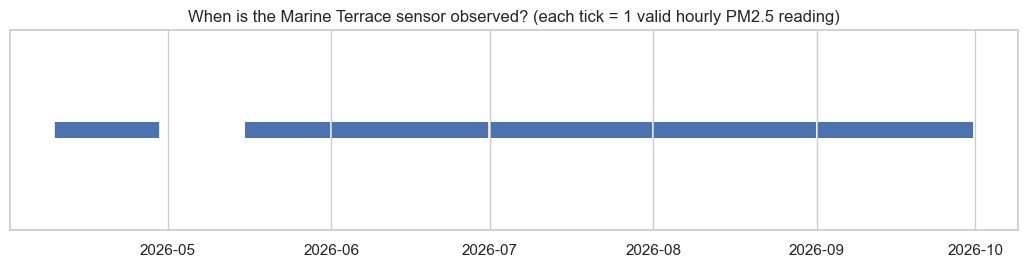

In [94]:
fig, ax = plt.subplots(figsize=(13, 2.6))
obs = hourly["pm25"].dropna().index
ax.scatter(obs, np.zeros(len(obs)), marker="|", s=120)
ax.set_yticks([]); ax.set_title("When is the Marine Terrace sensor observed? (each tick = 1 valid hourly PM2.5 reading)")
plt.show()

## Part 1 · 5. EDA: air quality

In [95]:
g = hourly["pm25"].groupby(hourly.index.to_period("M"))
monthly = pd.DataFrame({"observed_hours": g.count(), "mean": g.mean(), "p95": g.quantile(0.95), "max": g.max(),
                        "pct_hours_above_55": g.apply(lambda s: (s.dropna() > 55).mean() * 100),
                        "hours_above_150": g.apply(lambda s: int((s > 150).sum()))}).round(1)
print("PM2.5 by month (NEA 1-hour bands: Normal <=55, Elevated 56-150, High 151-250, Very High >250 ug/m3)")
display(monthly)
tot = hourly["pm25"].dropna()
print(f"Overall: mean {tot.mean():.1f}, median {tot.median():.1f}, max {tot.max():.1f} ug/m3 | "
      f"{(tot > 55).mean()*100:.1f}% of hours above 55, {int((tot > 150).sum())} hours above 150, {int((tot > 250).sum())} above 250")

PM2.5 by month (NEA 1-hour bands: Normal <=55, Elevated 56-150, High 151-250, Very High >250 ug/m3)


,observed_hours,mean,p95,max,pct_hours_above_55,hours_above_150
datetime,,,,,,
2026-04,466,14.5,31.2,160.2,0.9,1
2026-05,377,19.2,41.5,292.6,2.1,2
2026-06,702,12.6,33.1,213.8,1.1,1
2026-07,726,23.6,39.1,140.4,0.6,0
2026-08,726,32.7,48.4,130.6,2.2,0
2026-09,696,47.6,95.9,431.1,22.4,6


Overall: mean 26.2, median 24.3, max 431.1 ug/m3 | 5.3% of hours above 55, 10 hours above 150, 2 above 250


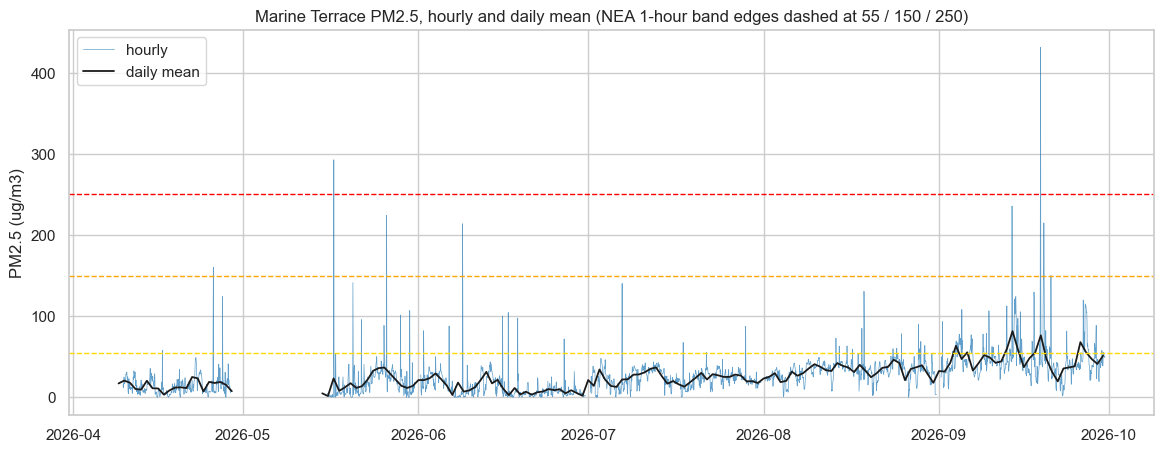

In [96]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(hourly.index, hourly["pm25"], lw=0.5, color="tab:blue", alpha=0.7, label="hourly")
ax.plot(hourly["pm25"].resample("D").mean().index, hourly["pm25"].resample("D").mean(), color="k", lw=1.3, label="daily mean")
for b, col in zip([55, 150, 250], ["gold", "orange", "red"]):
    ax.axhline(b, color=col, ls="--", lw=1)
ax.set_ylabel("PM2.5 (ug/m3)"); ax.set_title("Marine Terrace PM2.5, hourly and daily mean (NEA 1-hour band edges dashed at 55 / 150 / 250)")
ax.legend(loc="upper left"); plt.show()

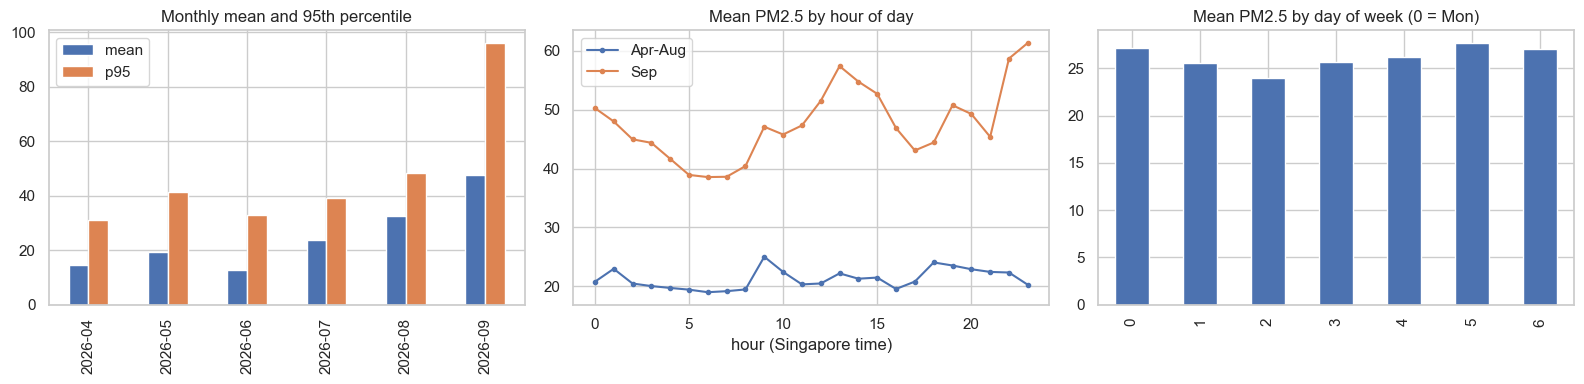

In [97]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
monthly[["mean", "p95"]].plot.bar(ax=axes[0]); axes[0].set_title("Monthly mean and 95th percentile"); axes[0].set_xlabel("")
d_ = hourly["pm25"]
early, late = d_[d_.index < "2026-09-01"], d_[d_.index >= "2026-09-01"]
early.groupby(early.index.hour).mean().plot(ax=axes[1], marker="o", ms=3, label="Apr-Aug")
late.groupby(late.index.hour).mean().plot(ax=axes[1], marker="o", ms=3, label="Sep")
axes[1].set_title("Mean PM2.5 by hour of day"); axes[1].legend(); axes[1].set_xlabel("hour (Singapore time)")
d_.groupby(d_.index.dayofweek).mean().plot.bar(ax=axes[2]); axes[2].set_title("Mean PM2.5 by day of week (0 = Mon)"); axes[2].set_xlabel("")
plt.tight_layout(); plt.show()

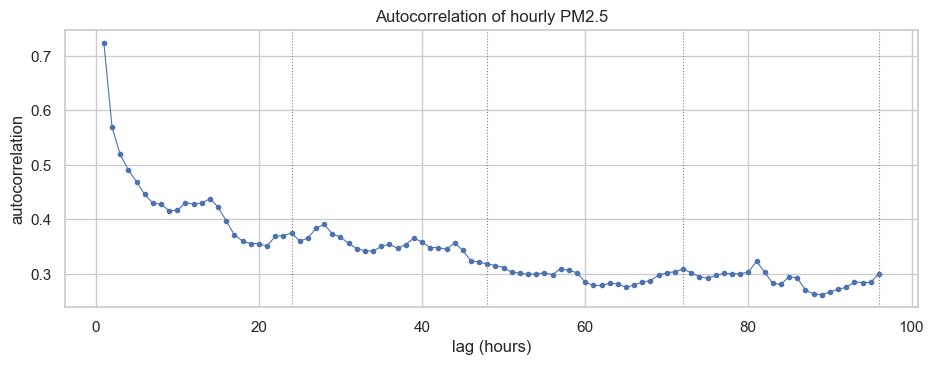

{'lag 1h': 0.724, 'lag 3h': 0.519, 'lag 6h': 0.446, 'lag 12h': 0.428, 'lag 24h': 0.375, 'lag 48h': 0.318, 'lag 72h': 0.309}


In [98]:
# Persistence: autocorrelation of hourly PM2.5
acf = pd.Series({k: hourly["pm25"].autocorr(k) for k in range(1, 97)})
ax = acf.plot(marker="o", ms=3, lw=0.8, figsize=(11, 3.6))
for k in (24, 48, 72, 96): ax.axvline(k, color="grey", ls=":", lw=0.8)
ax.set_xlabel("lag (hours)"); ax.set_ylabel("autocorrelation"); ax.set_title("Autocorrelation of hourly PM2.5"); plt.show()
print({f"lag {k}h": round(float(acf[k]), 3) for k in (1, 3, 6, 12, 24, 48, 72)})

In [99]:
# Episodes above the NEA 'Elevated' edge (55 ug/m3) and all hours above 150
ev = hourly["pm25"] > 55
grp = (ev != ev.shift()).cumsum()
ep = hourly[ev].groupby(grp[ev])["pm25"].agg(start=lambda s: s.index.min(), end=lambda s: s.index.max(), peak="max", mean="mean")
ep["hours"] = ((ep["end"] - ep["start"]) / H + 1).astype(int)
print(f"{len(ep)} episodes above 55 ug/m3 (consecutive hours); the 10 longest:")
display(ep.sort_values("hours", ascending=False).head(10).round(1).reset_index(drop=True))
hi = hourly.loc[hourly["pm25"] > 150, ["pm25", "pm1", "um003", "rh"]].round(1)
print(f"{len(hi)} hours above 150 ug/m3:"); display(hi)

74 episodes above 55 ug/m3 (consecutive hours); the 10 longest:


,start,end,peak,mean,hours
0,2026-09-26 12:00:00,2026-09-27 11:00:00,119.8,83.8,24
1,2026-09-04 11:00:00,2026-09-04 22:00:00,77.8,67.6,12
2,2026-09-14 05:00:00,2026-09-14 16:00:00,124.2,100.9,12
3,2026-09-14 18:00:00,2026-09-15 04:00:00,97.4,73.7,11
4,2026-09-06 11:00:00,2026-09-06 17:00:00,77.0,64.6,7
5,2026-09-19 09:00:00,2026-09-19 15:00:00,214.9,133.2,7
6,2026-09-03 22:00:00,2026-09-04 03:00:00,69.4,62.3,6
7,2026-09-06 19:00:00,2026-09-06 23:00:00,72.1,64.4,5
8,2026-09-08 18:00:00,2026-09-08 22:00:00,78.0,62.8,5
9,2026-09-28 12:00:00,2026-09-28 16:00:00,66.6,61.4,5


10 hours above 150 ug/m3:


parameter,pm25,pm1,um003,rh
datetime,,,,
2026-04-25 18:00:00,160.2,100.6,7488.0,50.0
2026-05-17 01:00:00,292.6,171.8,12460.0,61.0
2026-05-26 09:00:00,224.1,135.4,9857.0,58.0
2026-06-08 19:00:00,213.8,117.2,8885.0,58.0
2026-09-13 22:00:00,235.7,101.7,7916.0,50.0
2026-09-18 22:00:00,206.4,70.8,5930.0,53.0
2026-09-18 23:00:00,431.1,178.6,14282.0,54.0
2026-09-19 11:00:00,159.0,84.1,6280.0,59.0
2026-09-19 13:00:00,214.9,110.2,8324.0,55.0


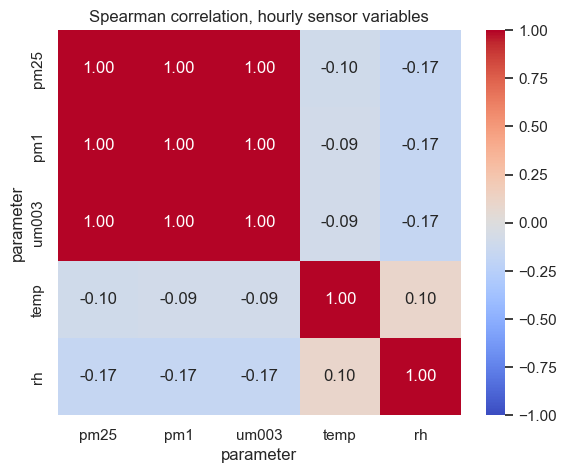

In [100]:
# Composition and sensor weather: hourly correlations
cols = ["pm25", "pm1", "um003", "temp", "rh"]
plt.figure(figsize=(6.5, 5))
sns.heatmap(hourly[cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation, hourly sensor variables"); plt.show()

## Part 1 · 6. EDA: weather (Marina Barrage daily) vs PM2.5
A day's weather is only known after the day ends, so for the forecasting features (Part 2) only **previous complete days** will be used. Here the exploration looks at same-day and previous-day links, using days with at least 18 hourly PM2.5 readings.

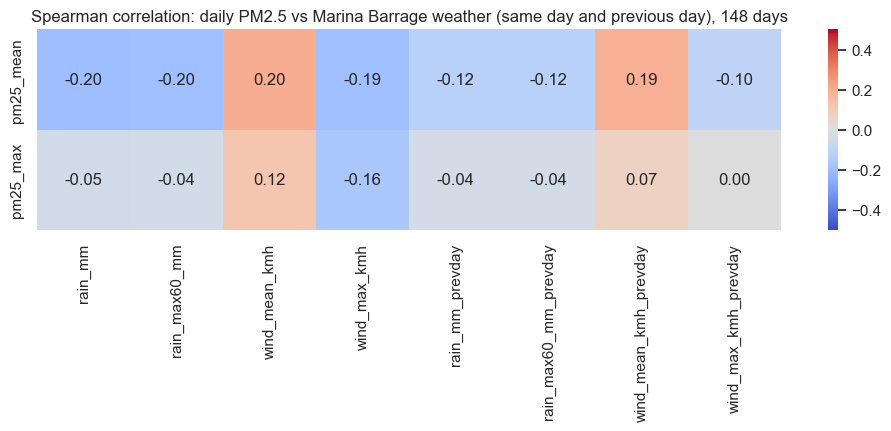

Daily mean PM2.5 by SAME-day rainfall:


,days,mean_pm25,median_pm25
rain_mm,,,
dry (0 mm),90,29.3,28.2
light (0-5),29,20.8,21.2
moderate (5-20),20,22.8,21.5
heavy (>20),9,24.0,19.8


Daily mean PM2.5 by PREVIOUS-day rainfall:


,days,mean_pm25,median_pm25
rain_mm_prevday,,,
dry (0 mm),89,28.1,26.3
light (0-5),31,23.3,25.3
moderate (5-20),18,23.5,19.8
heavy (>20),10,26.4,25.0


In [101]:
day = pd.DataFrame({"pm25_mean": hourly["pm25"].resample("D").mean(), "pm25_max": hourly["pm25"].resample("D").max(),
                    "obs_hours": hourly["pm25"].resample("D").count()})
day = day[day["obs_hours"] >= 18].drop(columns="obs_hours")
J = day.join(daily).join(daily.shift(1).add_suffix("_prevday")).dropna()
wcols = list(daily.columns) + [c + "_prevday" for c in daily.columns]
cm = J.corr(method="spearman").loc[["pm25_mean", "pm25_max"], wcols]
plt.figure(figsize=(12, 2.6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.5, vmax=0.5)
plt.title(f"Spearman correlation: daily PM2.5 vs Marina Barrage weather (same day and previous day), {len(J)} days"); plt.show()

def rain_class(s): return pd.cut(s, [-0.1, 0.1, 5, 20, 1000], labels=["dry (0 mm)", "light (0-5)", "moderate (5-20)", "heavy (>20)"])
t1 = J.groupby(rain_class(J["rain_mm"]))["pm25_mean"].agg(days="count", mean_pm25="mean", median_pm25="median").round(1)
t2 = J.groupby(rain_class(J["rain_mm_prevday"]))["pm25_mean"].agg(days="count", mean_pm25="mean", median_pm25="median").round(1)
print("Daily mean PM2.5 by SAME-day rainfall:"); display(t1)
print("Daily mean PM2.5 by PREVIOUS-day rainfall:"); display(t2)

## Part 1 · 7. Save cleaned data

In [102]:
hourly.to_csv("clean_hourly_marine_terrace.csv")
daily.to_csv("clean_daily_weather_marina_barrage.csv")
print("Saved clean_hourly_marine_terrace.csv", hourly.shape, "and clean_daily_weather_marina_barrage.csv", daily.shape)

Saved clean_hourly_marine_terrace.csv (4166, 5) and clean_daily_weather_marina_barrage.csv (273, 4)


In [103]:
print("=== PART 1 SUMMARY ===")
print(f"Air quality: {len(pm_files)} files, {len(raw)} raw rows, {n_invalid} invalid/zero values set to NaN")
print(f"Hourly grid: {len(hourly)} hours ({hourly.index.min():%Y-%m-%d} to {hourly.index.max():%Y-%m-%d}); PM2.5 observed {int(hourly.pm25.notna().sum())} h, missing {int(hourly.pm25.isna().sum())} h")
print(f"PM2.5: mean {tot.mean():.1f}, max {tot.max():.1f} ug/m3; {(tot > 55).mean()*100:.1f}% of hours above 55; {int((tot > 150).sum())} hours above 150")
print(f"Weather: {len(daily)} days, columns kept: {list(daily.columns)}")
print(f"Autocorrelation lag-24h {acf[24]:.2f}, lag-48h {acf[48]:.2f}")

=== PART 1 SUMMARY ===
Air quality: 6 files, 18270 raw rows, 121 invalid/zero values set to NaN
Hourly grid: 4166 hours (2026-04-09 to 2026-09-30); PM2.5 observed 3693 h, missing 473 h
PM2.5: mean 26.2, max 431.1 ug/m3; 5.3% of hours above 55; 10 hours above 150
Weather: 273 days, columns kept: ['rain_mm', 'rain_max60_mm', 'wind_mean_kmh', 'wind_max_kmh']
Autocorrelation lag-24h 0.37, lag-48h 0.32


---
# Part 2: Feature Engineering (Phase 3)

**Input:** `hourly` (Marine Terrace, regular hourly grid) and `daily` (Marina Barrage weather) from Part 1.
**Output:** `features_all.csv` = leakage-safe features + forecast targets (+24h, +48h) + chronological split labels.

At every *forecast origin* `t` the model only uses information available at or before `t` and predicts PM2.5 at `t+24h` and `t+48h`.

| Group | Features (all known at time `t`) |
|---|---|
| Lag | PM2.5 at t, t-1, t-3, t-6, t-12, t-24, t-48 |
| Rolling | 6h / 24h mean and std, 24h max / min, **7-day mean** |
| Change | 1h / 6h / 24h difference, deviation from the 24h and 7-day means |
| Composition and sensor weather | PM1, PM1/PM2.5 fine fraction, particle count, temperature, humidity (current, lag, 24h mean) |
| Daily weather (Marina Barrage) | rainfall and wind of the **previous complete days**: last-day rain, 3-day and 7-day rain, heaviest 60-min rain, mean wind, 3-day mean wind, max wind, days since 1 mm of rain |
| Calendar | hour of day (sin / cos), day of week, weekend flag |

**Timing rule for daily weather.** A day's summary is only complete at midnight, so on date D the model may only use days up to D-1. The leakage test below checks this explicitly.

**Not used:** month / season indicators. The test period (late September) is a month that never appears in training, so a month feature cannot generalise. Spatial aggregation across stations is not possible with a single sensor.

## Part 2 · 1. Configuration

In [104]:
HORIZONS = [24, 48]            # forecast horizons in hours
LAGS = [1, 3, 6, 12, 24, 48]   # lags of PM2.5 in hours
EVENT_THR = 55                 # NEA 1-hour "Elevated" edge: forecast above this = haze event
HIGH_THR = 150                 # NEA 1-hour "High" edge
TEST_FRAC, VAL_FRAC = 0.15, 0.15
PURGE = True                   # drop rows whose target window crosses a split boundary (prevents label leakage)
USE_DAY_OF_WEEK = True         # see the weekday check in section 7
assert (hourly.index.to_series().diff().dropna() == H).all()
print("Hourly rows:", len(hourly), "| daily weather days:", len(daily))

Hourly rows: 4166 | daily weather days: 273


## Part 2 · 2. Feature engineering
Every feature is a function of data up to time `t` only: `shift(k)` with k >= 0, trailing `rolling` windows, no centred windows and no future-looking fills.

In [105]:
def weather_features(dly, idx):
    d = dly.copy(); d.index = pd.to_datetime(d.index)
    assert d.index.is_monotonic_increasing and (d.index.to_series().diff().dropna() == pd.Timedelta("1D")).all()
    f = pd.DataFrame(index=d.index)
    f["wx_rain_prev"] = d["rain_mm"]
    f["wx_rain_sum3"] = d["rain_mm"].rolling(3, min_periods=3).sum()
    f["wx_rain_sum7"] = d["rain_mm"].rolling(7, min_periods=7).sum()
    f["wx_rain60_prev"] = d["rain_max60_mm"]
    f["wx_wind_prev"] = d["wind_mean_kmh"]
    f["wx_wind_mean3"] = d["wind_mean_kmh"].rolling(3, min_periods=3).mean()
    f["wx_gust_prev"] = d["wind_max_kmh"]
    dsr, c = [], 14
    for wet in (d["rain_mm"] >= 1.0):
        c = 0 if wet else min(c + 1, 14)
        dsr.append(c)
    f["wx_days_since_rain"] = dsr
    f.index = f.index + pd.Timedelta(days=1)          # the summary of day D is known from 00:00 of day D+1
    return f.reindex(idx, method="ffill")

def build_features(hr, dly):
    """Feature matrix. Row t uses only hourly data <= t and daily weather of days before t's date."""
    y = hr["pm25"]
    X = pd.DataFrame(index=hr.index)
    X["pm25_now"] = y
    for k in LAGS:
        X[f"pm25_lag{k}"] = y.shift(k)
    for w in (6, 24):
        r = y.rolling(w, min_periods=w)
        X[f"pm25_rollmean{w}"] = r.mean()
        X[f"pm25_rollstd{w}"] = r.std()
    X["pm25_rollmean168"] = y.rolling(168, min_periods=126).mean()     # 7-day baseline (needs 75% of hours)
    X["pm25_rollmax24"] = y.rolling(24, min_periods=24).max()
    X["pm25_rollmin24"] = y.rolling(24, min_periods=24).min()
    X["pm25_diff1"] = y.diff(1)
    X["pm25_diff6"] = y.diff(6)
    X["pm25_diff24"] = y.diff(24)
    X["pm25_vs_roll24"] = y - X["pm25_rollmean24"]
    X["pm25_vs_roll168"] = y - X["pm25_rollmean168"]
    X["pm1_now"] = hr["pm1"]
    X["fine_fraction"] = hr["pm1"] / y
    X["um003_now"] = hr["um003"]
    X["um003_lag24"] = hr["um003"].shift(24)
    X["temp_now"] = hr["temp"]
    X["temp_rollmean24"] = hr["temp"].rolling(24, min_periods=24).mean()
    X["rh_now"] = hr["rh"]
    X["rh_rollmean24"] = hr["rh"].rolling(24, min_periods=24).mean()
    X["rh_diff6"] = hr["rh"].diff(6)
    X = X.join(weather_features(dly, hr.index))
    hh = hr.index.hour
    X["hour_sin"] = np.sin(2 * np.pi * hh / 24)
    X["hour_cos"] = np.cos(2 * np.pi * hh / 24)
    X["dow"] = hr.index.dayofweek
    X["is_weekend"] = (hr.index.dayofweek >= 5).astype(int)
    return X

F = build_features(hourly, daily)
if not USE_DAY_OF_WEEK:
    F = F.rename(columns={"dow": "aux_dow", "is_weekend": "aux_is_weekend"})
FEATURES = [c for c in F.columns if not c.startswith("aux_")]
print("Feature matrix:", F.shape, "| model inputs:", len(FEATURES))

Feature matrix: (4166, 40) | model inputs: 40


## Part 2 · 3. Targets, event labels and the modelling table
- `target_h24` / `target_h48`: PM2.5 at `t+24h` / `t+48h`.
- `event_h*`: 1 if that future value exceeds 55 ug/m3 (NEA "Elevated"), the haze-event label for alerts. `high_h*`: above 150 (NEA "High").
- Rows are dropped when any feature is missing (start of the series, the first hours after each data gap). Rows without a target are excluded for that horizon.

In [106]:
T = pd.DataFrame(index=hourly.index)
for h in HORIZONS:
    tgt = hourly["pm25"].shift(-h)
    T[f"target_h{h}"] = tgt
    T[f"event_h{h}"] = (tgt > EVENT_THR).astype(float).where(tgt.notna())
    T[f"high_h{h}"] = (tgt > HIGH_THR).astype(float).where(tgt.notna())

data = F.join(T)
n0 = len(data)
data = data.dropna(subset=list(F.columns))
print(f"Rows: {n0} -> {len(data)} (dropped {n0 - len(data)} rows with missing features)")
print("Rows with a valid target: " + ", ".join(f"h{h}: {int(data[f'target_h{h}'].notna().sum())}" for h in HORIZONS))
print("Missing feature values left:", int(data[FEATURES].isna().sum().sum()))
data[["pm25_now", "pm25_lag24", "pm25_rollmean24", "wx_rain_prev", "wx_wind_mean3", "target_h24", "target_h48"]].tail(3)

Rows: 4166 -> 3275 (dropped 891 rows with missing features)
Rows with a valid target: h24: 3155, h48: 3107
Missing feature values left: 0


,pm25_now,pm25_lag24,pm25_rollmean24,wx_rain_prev,wx_wind_mean3,target_h24,target_h48
datetime,,,,,,,
2026-09-30 06:00:00,49.6,22.4,45.266667,0.0,5.133333,NaN,NaN
2026-09-30 07:00:00,49.3,19.5,46.508333,0.0,5.133333,NaN,NaN
2026-09-30 08:00:00,50.1,30.8,47.312500,0.0,5.133333,NaN,NaN


## Part 2 · 4. Leakage tests
1. **Features use only the past.** For random forecast origins `t`, rebuild the features from the hourly data up to `t` and only the **completed days before `t`'s date**. The row for `t` must equal the one built from the full data. If any feature used the future (including the weather of `t`'s own day) the rows would differ.
2. **Targets are aligned.** `target_hH` at `t` equals the PM2.5 observed H hours later.

In [107]:
def leakage_check(n_checks=40, seed=0):
    rng = np.random.default_rng(seed)
    full = build_features(hourly, daily)
    cand = full.dropna().index
    picks = rng.choice(len(cand), size=min(n_checks, len(cand)), replace=False)
    bad = []
    for i in picks:
        t = pd.Timestamp(cand[i])
        known_days = daily.loc[: t.normalize() - pd.Timedelta(days=1)]       # only completed days are known at t
        trunc = build_features(hourly.loc[:t], known_days)
        if not np.allclose(trunc.loc[t].values.astype(float), full.loc[t].values.astype(float), equal_nan=True):
            bad.append(t)
    return bad

leaks = leakage_check()
assert not leaks, f"Future information leaks into features at: {leaks[:5]}"
print("Test 1 passed: features at t are identical when everything after t (and t's own day of weather) is removed (40 random origins).")

for h in HORIZONS:
    d = data[data[f"target_h{h}"].notna()]
    sample = d.index[::53]
    assert np.allclose(d.loc[sample, f"target_h{h}"].values, hourly["pm25"].reindex(sample + h * H).values)
print("Test 2 passed: targets equal PM2.5 observed H hours later.")

Test 1 passed: features at t are identical when everything after t (and t's own day of weather) is removed (40 random origins).
Test 2 passed: targets equal PM2.5 observed H hours later.


## Part 2 · 5. Chronological train / validation / test split (no shuffling)
Test = last 15% of usable rows, validation = the 15% before it, training = everything earlier.

**Purging:** the target of a row at `t` is the value at `t+h`. Rows whose target lies in the next period are dropped (`PURGE=True`), so no label crosses a boundary.

In [108]:
def make_split(idx, h, test_frac=TEST_FRAC, val_frac=VAL_FRAC, purge=PURGE):
    n = len(idx)
    test_start = idx[n - int(round(test_frac * n))]
    val_start = idx[n - int(round((test_frac + val_frac) * n))]
    s = pd.Series("train", index=idx)
    s[idx >= val_start] = "val"
    s[idx >= test_start] = "test"
    if purge:
        td = h * H
        s[(s == "train").values & (idx + td >= val_start)] = "purged"
        s[(s == "val").values & (idx + td >= test_start)] = "purged"
    return s

for h in HORIZONS:
    rows = data.index[data[f"target_h{h}"].notna()]
    sp = make_split(rows, h)
    data[f"split_h{h}"] = sp.reindex(data.index).fillna("no_target")
    tr, va, te = (sp.index[sp == k] for k in ("train", "val", "test"))
    assert tr.max() < va.min() and va.max() < te.min()
    if PURGE:
        assert tr.max() + h * H < va.min() and va.max() + h * H < te.min()

rows_out = []
for h in HORIZONS:
    for k in ["train", "val", "test", "purged"]:
        d = data[data[f"split_h{h}"] == k]
        rows_out.append({"horizon": f"+{h}h", "split": k, "rows": len(d), "from": d.index.min(), "to": d.index.max(),
                         "target_mean": d[f"target_h{h}"].mean(), "target_max": d[f"target_h{h}"].max(),
                         "hours>55": int(d[f"event_h{h}"].sum()), "hours>150": int(d[f"high_h{h}"].sum())})
split_table = pd.DataFrame(rows_out).round(1)
display(split_table)
for h in HORIZONS:
    m = split_table[split_table.horizon == f"+{h}h"].set_index("split")["target_mean"]
    print(f"+{h}h mean target: train {m['train']} | val {m['val']} | test {m['test']}  (large gaps = regime shift)")

,horizon,split,rows,from,to,target_mean,target_max,hours>55,hours>150
0,+24h,train,2185,2026-04-15 00:00:00,2026-08-16 16:00:00,20.1,224.1,24,3
1,+24h,val,449,2026-08-17 17:00:00,2026-09-08 15:00:00,37.9,130.6,48,0
2,+24h,test,473,2026-09-09 16:00:00,2026-09-29 08:00:00,48.7,431.1,102,6
3,+24h,purged,48,2026-08-16 17:00:00,2026-09-09 15:00:00,43.4,106.6,9,0
4,+48h,train,2127,2026-04-15 00:00:00,2026-08-15 06:00:00,20.1,224.1,24,3
5,+48h,val,418,2026-08-17 07:00:00,2026-09-06 22:00:00,36.0,93.3,32,0
6,+48h,test,466,2026-09-08 23:00:00,2026-09-28 08:00:00,48.7,431.1,102,6
7,+48h,purged,96,2026-08-15 07:00:00,2026-09-08 22:00:00,43.1,130.6,12,0


+24h mean target: train 20.1 | val 37.9 | test 48.7  (large gaps = regime shift)
+48h mean target: train 20.1 | val 36.0 | test 48.7  (large gaps = regime shift)


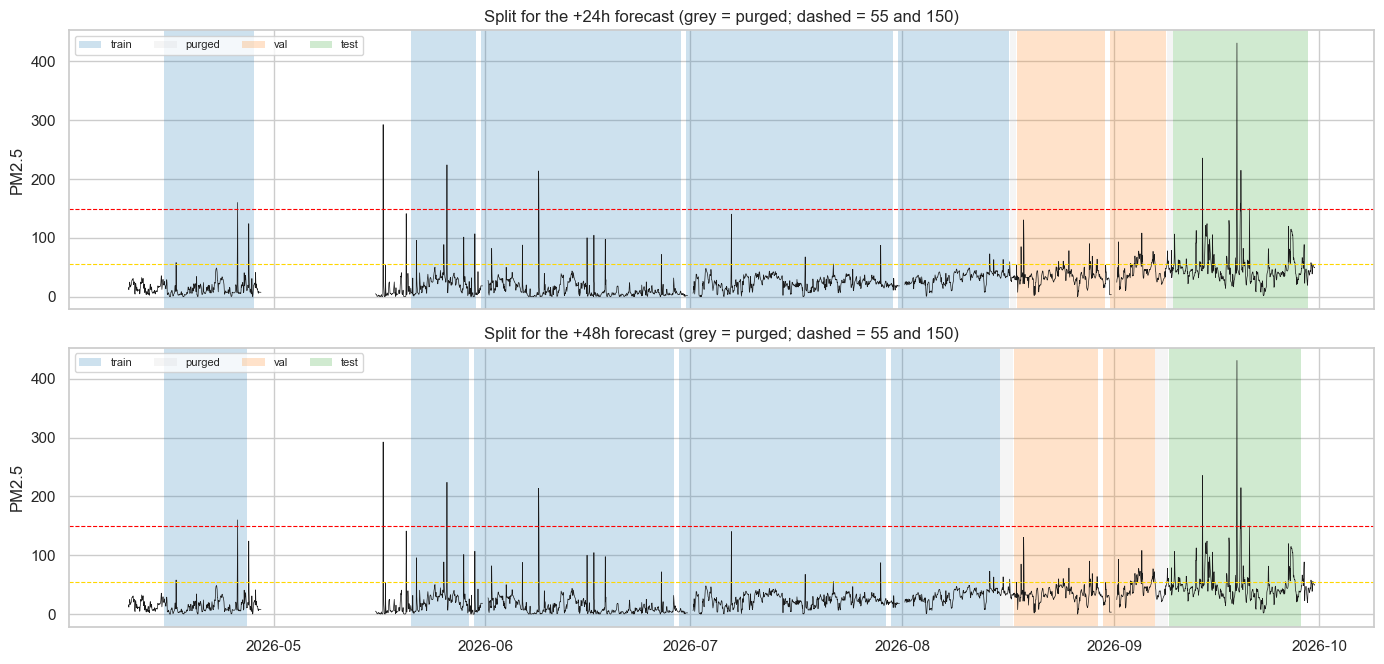

In [109]:
def runs(s):
    grp = (s != s.shift()).cumsum()
    for _, g in s.groupby(grp):
        yield g.iloc[0], g.index[0], g.index[-1]

colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green", "purged": "lightgrey"}
fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(14, 3.4 * len(HORIZONS)), sharex=True)
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    ax.plot(hourly.index, hourly["pm25"], color="k", lw=0.5)
    for lab, a, b in runs(data[f"split_h{h}"]):
        if lab in colors:
            ax.axvspan(a, b, color=colors[lab], alpha=0.22, lw=0, label=lab)
    ax.axhline(EVENT_THR, color="gold", ls="--", lw=0.8); ax.axhline(HIGH_THR, color="red", ls="--", lw=0.8)
    h_, l_ = ax.get_legend_handles_labels(); uniq = dict(zip(l_, h_))
    ax.legend(uniq.values(), uniq.keys(), ncol=4, fontsize=8, loc="upper left")
    ax.set_title(f"Split for the +{h}h forecast (grey = purged; dashed = 55 and 150)"); ax.set_ylabel("PM2.5")
plt.tight_layout(); plt.show()

## Part 2 · 6. Feature groups and dictionary
What each input means in plain words, and why it can help forecast PM2.5 a day or two ahead.

In [110]:
import re
def group_of(c):
    if c.startswith(("hour_", "dow", "is_weekend")): return "calendar"
    if c.startswith("wx_"): return "daily weather"
    if c.startswith(("pm1", "fine", "um003", "temp", "rh")): return "composition & sensor weather"
    if c in ("pm25_now", "pm25_diff1", "pm25_diff6", "pm25_diff24", "pm25_vs_roll24", "pm25_vs_roll168"): return "level & change"
    if "_lag" in c: return "lag"
    return "rolling"

groups = pd.Series({c: group_of(c) for c in FEATURES})
STATIC = {
    "pm25_now": ("PM2.5 at the forecast origin", "Haze persists for hours to days, so the current level is the starting point"),
    "pm25_rollmean168": ("Average PM2.5 over the last 7 days", "Slow baseline: separates a clean week from a hazy one"),
    "pm25_rollmax24": ("Highest PM2.5 in the last 24 h", "Recent peak: did a spike just happen"),
    "pm25_rollmin24": ("Lowest PM2.5 in the last 24 h", "Recent floor: how clean the air got"),
    "pm25_diff1": ("Change over the last 1 h", "Momentum: building or clearing right now"),
    "pm25_diff6": ("Change over the last 6 h", "Medium-term trend"),
    "pm25_diff24": ("Change over the last 24 h", "Day-on-day trend"),
    "pm25_vs_roll24": ("Current PM2.5 minus its 24 h average", "How far above or below the recent baseline"),
    "pm25_vs_roll168": ("Current PM2.5 minus its 7-day average", "How unusual the current level is for this week"),
    "pm1_now": ("PM1 (finest particles)", "Combustion smoke is dominated by very fine particles"),
    "fine_fraction": ("PM1 / PM2.5 ratio", "Share of very fine particles: separates smoke-like from coarse / dust-like air"),
    "um003_now": ("Particle count (0.3 um and larger) per cm3", "Counts particles instead of weighing them, so it reacts early to a new plume"),
    "um003_lag24": ("Particle count 24 h earlier", "Same hour yesterday"),
    "temp_now": ("Sensor temperature now", "Weather context (heat, sun, rain)"),
    "temp_rollmean24": ("Average temperature, last 24 h", "Smoothed weather context"),
    "rh_now": ("Relative humidity now", "Humid air and rain wash out or swell particles; also a known optical-sensor bias"),
    "rh_rollmean24": ("Average humidity, last 24 h", "Smoothed weather context"),
    "rh_diff6": ("Change in humidity over 6 h", "Showers and fronts appear as humidity jumps"),
    "wx_rain_prev": ("Rainfall total of the last complete day (mm)", "Rain washes particles out of the air"),
    "wx_rain_sum3": ("Rainfall over the last 3 complete days (mm)", "Recent wet spell"),
    "wx_rain_sum7": ("Rainfall over the last 7 complete days (mm)", "Wet or dry week"),
    "wx_rain60_prev": ("Heaviest 60-min rainfall of the last complete day (mm)", "Shower intensity"),
    "wx_wind_prev": ("Mean wind speed of the last complete day (km/h)", "Stronger wind disperses haze; calm days let it build up"),
    "wx_wind_mean3": ("Mean wind speed over the last 3 complete days (km/h)", "Smoothed ventilation"),
    "wx_gust_prev": ("Max wind speed of the last complete day (km/h)", "Gusts and squall lines"),
    "wx_days_since_rain": ("Days since a day with at least 1 mm of rain (max 14)", "Long dry spells let particles accumulate"),
    "hour_sin": ("Hour of day, sine part", "Daily cycle; the sine / cosine pair avoids a jump at midnight"),
    "hour_cos": ("Hour of day, cosine part", "Pairs with hour_sin"),
    "dow": ("Day of week (0 = Monday)", "Weekly activity cycle (traffic, industry)"),
    "is_weekend": ("Saturday or Sunday", "Weekend activity pattern"),
}
def describe(c):
    if c in STATIC: return STATIC[c]
    m = re.fullmatch(r"pm25_lag(\d+)", c)
    if m:
        k = int(m.group(1))
        return (f"PM2.5 {k} h before the origin",
                "Same hour yesterday / the day before: daily pattern and multi-day persistence" if k in (24, 48) else "Recent history: short-term persistence and trend")
    m = re.fullmatch(r"pm25_rollmean(\d+)", c)
    if m: return (f"Average PM2.5 over the last {m.group(1)} h", "Smooths sensor noise; recent baseline")
    m = re.fullmatch(r"pm25_rollstd(\d+)", c)
    if m: return (f"Standard deviation of PM2.5 over the last {m.group(1)} h", "Volatility: unsettled air often accompanies spikes")
    raise KeyError(f"no description for {c}")

fd = pd.DataFrame({c: (groups[c], *describe(c)) for c in FEATURES}, index=["group", "what it is", "why it may help"]).T.sort_values("group", kind="stable")
assert len(fd) == len(FEATURES)
display(groups.value_counts().rename("n_features").to_frame())
with pd.option_context("display.max_rows", 80, "display.max_colwidth", 90, "display.width", 250):
    display(fd)

,n_features
composition & sensor weather,9
daily weather,8
rolling,7
level & change,6
lag,6
calendar,4


,group,what it is,why it may help
hour_sin,calendar,"Hour of day, sine part",Daily cycle; the sine / cosine pair avoids a jump at midnight
hour_cos,calendar,"Hour of day, cosine part",Pairs with hour_sin
dow,calendar,Day of week (0 = Monday),"Weekly activity cycle (traffic, industry)"
is_weekend,calendar,Saturday or Sunday,Weekend activity pattern
pm1_now,composition & sensor weather,PM1 (finest particles),Combustion smoke is dominated by very fine particles
fine_fraction,composition & sensor weather,PM1 / PM2.5 ratio,Share of very fine particles: separates smoke-like from coarse / dust-like air
um003_now,composition & sensor weather,Particle count (0.3 um and larger) per cm3,"Counts particles instead of weighing them, so it reacts early to a new plume"
um003_lag24,composition & sensor weather,Particle count 24 h earlier,Same hour yesterday
temp_now,composition & sensor weather,Sensor temperature now,"Weather context (heat, sun, rain)"
temp_rollmean24,composition & sensor weather,"Average temperature, last 24 h",Smoothed weather context


## Part 2 · 7. Train-only relationships
Everything here uses the **training rows only**, so nothing about validation or test influences feature decisions.

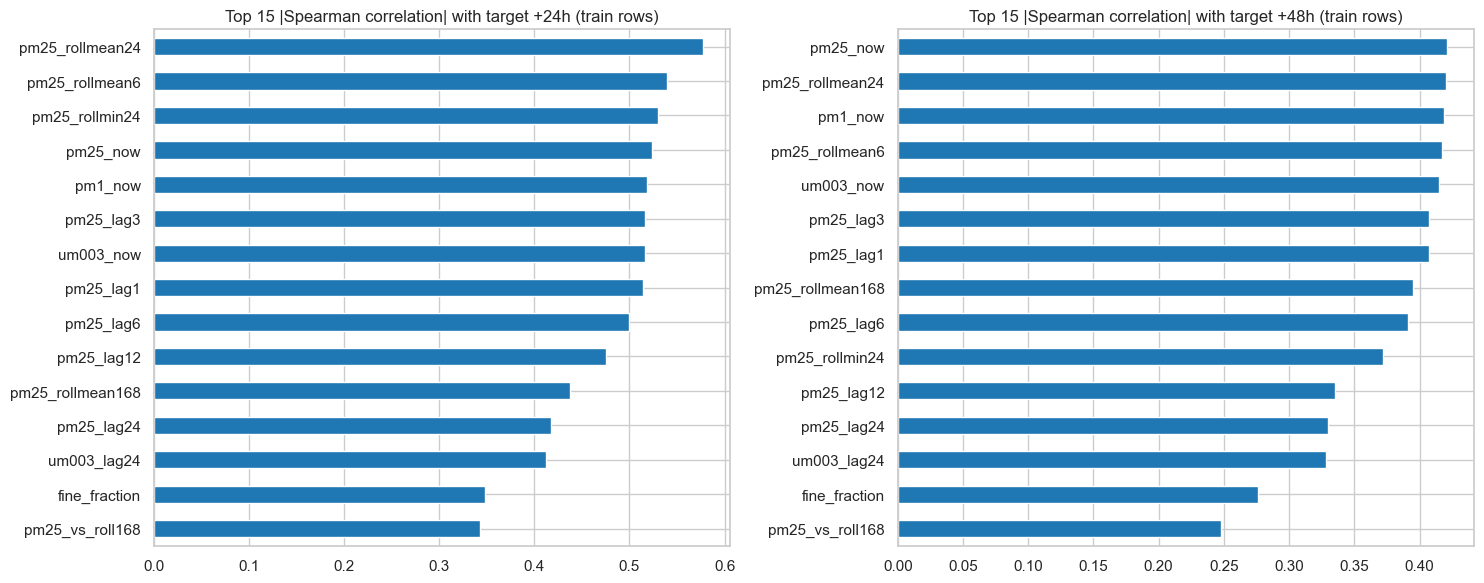

Daily-weather features vs +24h target (train, Spearman):


,spearman_with_target_h24
wx_rain_sum7,-0.219
wx_rain_sum3,-0.084
wx_gust_prev,-0.021
wx_rain60_prev,-0.007
wx_rain_prev,-0.004
wx_days_since_rain,0.002
wx_wind_prev,0.227
wx_wind_mean3,0.236


In [111]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(15, 6))
for ax, h in zip(axes, HORIZONS):
    tr = data[data[f"split_h{h}"] == "train"]
    corr = tr[FEATURES].corrwith(tr[f"target_h{h}"], method="spearman").sort_values(key=abs, ascending=False).head(15)[::-1]
    corr.plot.barh(ax=ax, color=["tab:red" if v < 0 else "tab:blue" for v in corr])
    ax.set_title(f"Top 15 |Spearman correlation| with target +{h}h (train rows)")
plt.tight_layout(); plt.show()

wx_feats = [c for c in FEATURES if c.startswith("wx_")]
tr24 = data[data["split_h24"] == "train"]
print("Daily-weather features vs +24h target (train, Spearman):")
display(tr24[wx_feats].corrwith(tr24["target_h24"], method="spearman").round(3).to_frame("spearman_with_target_h24").sort_values("spearman_with_target_h24"))

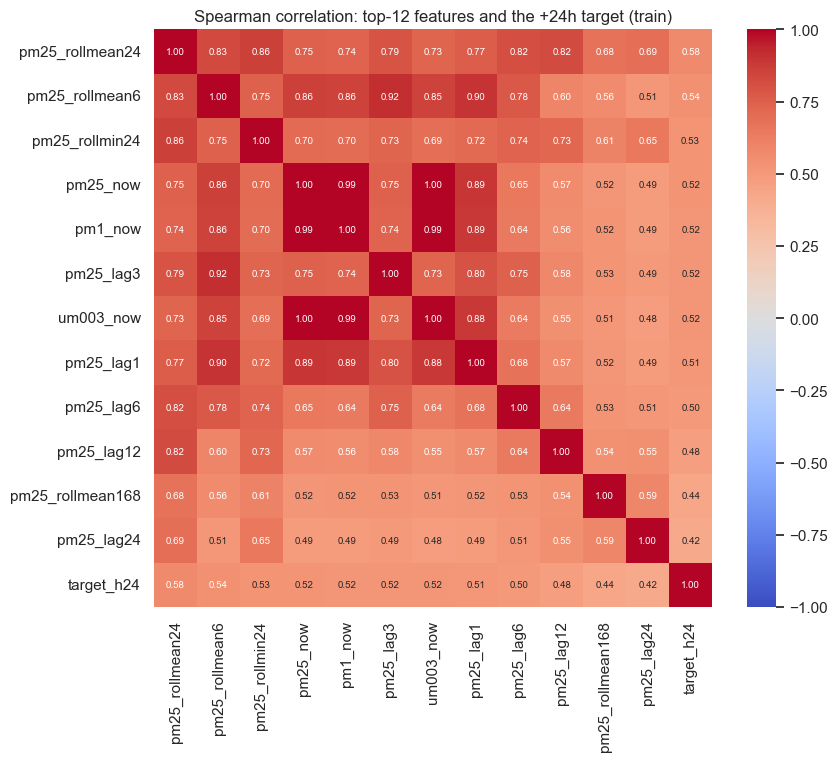

In [112]:
# Heatmap: the 12 strongest features + the target (train rows, +24h). Shows which features carry the same information.
top = tr24[FEATURES].corrwith(tr24["target_h24"], method="spearman").abs().sort_values(ascending=False).head(12).index.tolist()
plt.figure(figsize=(9, 7.5))
sns.heatmap(tr24[top + ["target_h24"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Spearman correlation: top-12 features and the +24h target (train)"); plt.show()

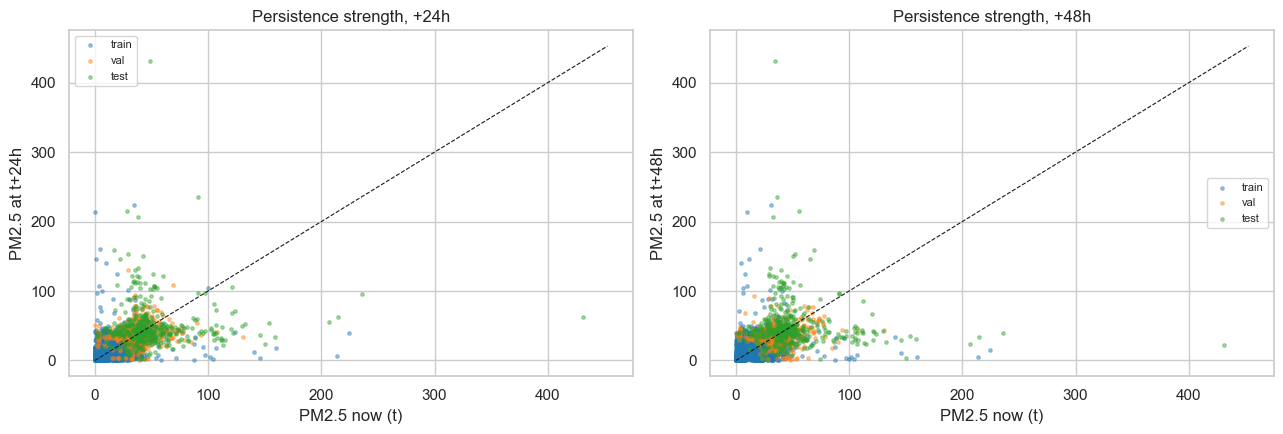

In [113]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(13, 4.5))
for ax, h in zip(axes, HORIZONS):
    for k in ["train", "val", "test"]:
        d = data[data[f"split_h{h}"] == k]
        ax.scatter(d["pm25_now"], d[f"target_h{h}"], s=6, alpha=0.4, color=colors[k], label=k)
    lim = [0, data["pm25_now"].max() * 1.05]
    ax.plot(lim, lim, "k--", lw=0.8); ax.set_xlabel("PM2.5 now (t)"); ax.set_ylabel(f"PM2.5 at t+{h}h")
    ax.set_title(f"Persistence strength, +{h}h"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [114]:
# Weekday check on training rows: is there a weekly pattern, and how many distinct dates back it?
trw = data[data["split_h24"] == "train"]
chk = trw.groupby("dow")["target_h24"].agg(mean_target="mean", median_target="median", hours="count").round(1)
chk["distinct_dates"] = trw.groupby("dow").apply(lambda d: d.index.normalize().nunique())
chk.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][:len(chk)] if len(chk) == 7 else chk.index
display(chk)

,mean_target,median_target,hours,distinct_dates
Mon,19.8,19.1,294,13
Tue,19.0,18.8,281,14
Wed,21.2,20.0,303,13
Thu,18.6,17.2,330,15
Fri,19.8,17.8,333,15
Sat,19.8,19.4,327,14
Sun,22.3,20.8,317,15


## Part 2 · 8. Sanity baselines (preview of Phase 4)
Simple reference forecasts show what any model must beat. For +24h and +48h the "seasonal naive" forecast (same hour one or two days before the target) is identical to persistence of the current value. Formal evaluation is in Part 3.

In [115]:
rows_out = []
for h in HORIZONS:
    tr = data[data[f"split_h{h}"] == "train"]
    train_mean = tr[f"target_h{h}"].mean()
    for sp in ["val", "test"]:
        d = data[data[f"split_h{h}"] == sp]; yv = d[f"target_h{h}"]
        for name, p in {"persistence (value now)": d["pm25_now"], "24h trailing mean": d["pm25_rollmean24"],
                        "7-day trailing mean": d["pm25_rollmean168"], "train mean": pd.Series(train_mean, index=d.index)}.items():
            rows_out.append({"horizon": f"+{h}h", "split": sp, "baseline": name, "RMSE": np.sqrt(((yv - p) ** 2).mean()), "MAE": (yv - p).abs().mean()})
display(pd.DataFrame(rows_out).pivot_table(index=["horizon", "baseline"], columns="split", values=["RMSE", "MAE"]).round(1))

MAE        RMSE      
split                            test   val  test   val
horizon baseline                                       
+24h    24h trailing mean        22.8  13.2  36.4  17.3
        7-day trailing mean      19.7  11.4  33.8  15.9
        persistence (value now)  27.3  15.1  45.4  19.9
        train mean               29.6  19.5  43.5  23.6
+48h    24h trailing mean        26.0  12.6  40.1  16.5
        7-day trailing mean      20.4  10.8  34.4  14.4
        persistence (value now)  28.2  14.8  48.3  19.9
        train mean               29.5  17.8  43.6  21.2

## Part 2 · 9. Save the modelling table

In [116]:
out = data.copy(); out.index.name = "datetime"
out.to_csv("features_all.csv")
print("Saved features_all.csv", out.shape, "| feature columns:", len(FEATURES))

print("=== PART 2 SUMMARY ===")
print(f"Features: {len(FEATURES)} in {groups.nunique()} groups | modelling rows: {len(data)} (dropped {n0 - len(data)} with missing features)")
for h in HORIZONS:
    c = data[f"split_h{h}"].value_counts()
    print(f"+{h}h  train {c.get('train',0)} | val {c.get('val',0)} | test {c.get('test',0)} | purged {c.get('purged',0)} | no target {c.get('no_target',0)}"
          f" | hours>55 in test: {int(data.loc[data[f'split_h{h}']=='test', f'event_h{h}'].sum())}, >150: {int(data.loc[data[f'split_h{h}']=='test', f'high_h{h}'].sum())}")
print("Leakage tests: passed")

Saved features_all.csv (3275, 48) | feature columns: 40
=== PART 2 SUMMARY ===
Features: 40 in 6 groups | modelling rows: 3275 (dropped 891 with missing features)
+24h  train 2185 | val 449 | test 473 | purged 48 | no target 120 | hours>55 in test: 102, >150: 6
+48h  train 2127 | val 418 | test 466 | purged 96 | no target 168 | hours>55 in test: 102, >150: 6
Leakage tests: passed


---
# Part 3: Baselines and Candidate Models (Phase 4)

**Evaluation protocol (same for every model)**
- For each horizon `h` (+24h, +48h) and each forecast origin `t` in the validation or test period, a model may use data **up to `t` only** (plus completed days of weather) and must predict PM2.5 at `t+h`.
- Every model is trained / fitted on the **training rows only**. Validation is used to compare models; the **test set is only reported, never used to choose anything**.
- Metrics: RMSE and MAE (primary), MAPE (valid because PM2.5 is never zero after cleaning), and *skill vs naive* = 1 - RMSE / RMSE(naive).

**Models**

| Type | Model | Notes |
|---|---|---|
| Baseline | Naive: y(t+h) = y(t) | For h = 24 and 48 the *seasonal naive* forecast is exactly this value |
| Baseline | 24h and 7-day moving averages | Stronger references than naive when the series is noisy |
| Classical | SARIMAX(1,1,1) + daily cycle | Hour-of-day sine / cosine as exogenous inputs; parameters fitted on train, then applied to the last 14 days of data before each origin (no refit) |
| Exp. smoothing | Holt-Winters | Damped additive trend, additive daily seasonality (24 h), parameters fitted on train |
| ML | LightGBM, variants a / b / c | (a) level and (b) change from now, both with all features; (c) **scale-free**: ratio-type features and the log of the ratio y(t+h) / y(t) |
| ML | Ridge, scale-free | Same inputs and target as (c), a low-variance linear model |
| Ablation | (c) and Ridge with / without daily weather | Isolates what rain and wind add |

In [117]:
!pip -q install lightgbm statsmodels scikit-learn
import time
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def split_idx(h, sp):  return data.index[data[f"split_h{h}"] == sp]
def eval_idx(h):       return data.index[data[f"split_h{h}"].isin(["val", "test"])]
def actual(h, idx):    return data.loc[idx, f"target_h{h}"]

preds = {h: {} for h in HORIZONS}     # preds[h][model] = Series indexed by forecast origin (val + test)
fitted = {}                           # fitted ML models, kept for interpretation later
print("Horizons:", HORIZONS, "| features for the all-feature ML models:", len(FEATURES))

Horizons: [24, 48] | features for the all-feature ML models: 40


## Part 3 · 1. Baselines

In [118]:
for h in HORIZONS:
    ix = eval_idx(h)
    preds[h]["Naive (y_t)"] = data.loc[ix, "pm25_now"]
    preds[h]["24h moving average"] = data.loc[ix, "pm25_rollmean24"]
    preds[h]["7-day moving average"] = data.loc[ix, "pm25_rollmean168"]
print({h: list(v) for h, v in preds.items()})

{24: ['Naive (y_t)', '24h moving average', '7-day moving average'], 48: ['Naive (y_t)', '24h moving average', '7-day moving average']}


## Part 3 · 2. Input series for the classical models
SARIMAX and Holt-Winters need an unbroken series. Gaps of up to 30 h are bridged by time interpolation **for these two models' input windows only**. This uses data on both sides of a gap, but every such gap lies before the origin being forecast, so nothing after the origin is used. The 17-day outage is not bridged: the models are fitted only on the data after it.

In [119]:
y = hourly["pm25"].asfreq("h")
y_cls = y.interpolate(method="time", limit=30, limit_area="inside")

val_min = min(split_idx(h, "val").min() for h in HORIZONS)
nan_before = y_cls[y_cls.isna() & (y_cls.index < val_min)].index
start_cls = (nan_before.max() + H) if len(nan_before) else y_cls.index[0]
print("Classical models are fitted on data from", start_cls, "onwards (after the last gap longer than 30 h)")
WINDOW = 14 * 24

Classical models are fitted on data from 2026-05-15 22:00:00 onwards (after the last gap longer than 30 h)


## Part 3 · 3. SARIMAX (classical)
Fitted once on the training period. For each forecast origin the *same parameters* are applied to the preceding 14 days, and a forecast `h` steps ahead is produced. The model is never re-estimated on validation or test information.

In [120]:
def hour_exog(idx):
    hr = np.asarray(idx.hour)
    return pd.DataFrame({"hr_sin": np.sin(2 * np.pi * hr / 24), "hr_cos": np.cos(2 * np.pi * hr / 24)}, index=idx)

def window_at(t):
    w = y_cls.loc[t - WINDOW * H: t]
    return w.ffill().bfill() if w.isna().any() else w

SARIMAX_ORDER = (1, 1, 1)
t0 = time.time()
for h in HORIZONS:
    fit_end = split_idx(h, "train").max() + h * H
    y_fit = y_cls.loc[start_cls:fit_end]
    base = SARIMAX(y_fit, exog=hour_exog(y_fit.index), order=SARIMAX_ORDER).fit(disp=False)
    out = {}
    for t in eval_idx(h):
        w = window_at(t)
        r = base.apply(w, exog=hour_exog(w.index), refit=False)
        fut = pd.date_range(t + H, periods=h, freq="h")
        out[t] = float(r.forecast(steps=h, exog=hour_exog(fut)).iloc[-1])
    preds[h]["SARIMAX(1,1,1)+daily cycle"] = pd.Series(out).clip(lower=0)
    print(f"+{h}h SARIMAX done: AIC on train {base.aic:.0f}, params {dict(base.params.round(3))}")
print(f"{time.time() - t0:.0f}s")

+24h SARIMAX done: AIC on train 17922, params {'hr_sin': np.float64(-0.672), 'hr_cos': np.float64(0.915), 'ar.L1': np.float64(0.393), 'ma.L1': np.float64(-0.949), 'sigma2': np.float64(167.761)}
+48h SARIMAX done: AIC on train 17852, params {'hr_sin': np.float64(-0.688), 'hr_cos': np.float64(0.909), 'ar.L1': np.float64(0.393), 'ma.L1': np.float64(-0.95), 'sigma2': np.float64(168.459)}
16s


## Part 3 · 4. Holt-Winters exponential smoothing
Damped additive trend with additive daily seasonality (24 h). The smoothing parameters are fitted on the training period; for each origin the filter runs over the preceding 14 days with those parameters fixed.

In [121]:
HW_KW = dict(trend="add", damped_trend=True, seasonal="add", seasonal_periods=24)
def hw_param(res, *names):
    for n in names:
        if n in res.params and res.params[n] is not None:
            return float(res.params[n])
    raise KeyError(names)

t0 = time.time()
for h in HORIZONS:
    fit_end = split_idx(h, "train").max() + h * H
    y_fit = y_cls.loc[start_cls:fit_end]
    assert y_fit.notna().all()
    hw0 = ExponentialSmoothing(y_fit, initialization_method="estimated", **HW_KW).fit()
    prm = dict(smoothing_level=hw_param(hw0, "smoothing_level"),
               smoothing_trend=hw_param(hw0, "smoothing_trend", "smoothing_slope"),
               smoothing_seasonal=hw_param(hw0, "smoothing_seasonal"),
               damping_trend=hw_param(hw0, "damping_trend", "damping_slope"))
    out = {}
    for t in eval_idx(h):
        m = ExponentialSmoothing(window_at(t), initialization_method="heuristic", **HW_KW).fit(optimized=False, **prm)
        out[t] = float(m.forecast(h).iloc[-1])
    preds[h]["Holt-Winters (damped, s=24)"] = pd.Series(out).clip(lower=0)
    print(f"+{h}h Holt-Winters done: " + ", ".join(f"{k}={v:.3f}" for k, v in prm.items()))
print(f"{time.time() - t0:.0f}s")

+24h Holt-Winters done: smoothing_level=0.295, smoothing_trend=0.000, smoothing_seasonal=0.000, damping_trend=0.954
+48h Holt-Winters done: smoothing_level=0.295, smoothing_trend=0.000, smoothing_seasonal=0.000, damping_trend=0.955
12s


## Part 3 · 5. Machine learning: LightGBM and Ridge
Default (untuned) settings; tuning is Phase 5. Ridge standardises features with **training rows only** (inside the pipeline).

**Why several variants?** The training period (April to August) is much calmer than validation and test, so models built on absolute levels have to extrapolate. Variants (a) and (b) use all absolute-level features and show what happens. Variant (c) uses **scale-free** inputs (ratios to the 24 h and 7-day means, PM1/PM2.5, hour of day) and predicts the **log of the ratio** y(t+h) / y(t), which behaves the same at 20 or 80 ug/m3. A second version adds three daily-weather inputs (log of 3-day rain, 3-day mean wind, days since rain) so that the effect of weather can be read off directly. Design (c) was inspired by a failure seen on validation data in an earlier iteration of this project, so its validation scores may be slightly optimistic; the test set played no role.

In [122]:
LGB_PARAMS = dict(n_estimators=200, learning_rate=0.03, num_leaves=7, min_child_samples=20,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
                  random_state=42, verbose=-1)
make_lgb = lambda: lgb.LGBMRegressor(**LGB_PARAMS)
make_ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=100.0))

XA = data[FEATURES]
ma24, ma168 = data["pm25_rollmean24"], data["pm25_rollmean168"]
XR = pd.DataFrame({
    "rel_now_ma24":   data["pm25_now"] / ma24,
    "rel_ma6_ma24":   data["pm25_rollmean6"] / ma24,
    "rel_lag24_ma24": data["pm25_lag24"] / ma24,
    "rel_lag48_ma24": data["pm25_lag48"] / ma24,
    "rel_max24_ma24": data["pm25_rollmax24"] / ma24,
    "rel_diff6_ma24": data["pm25_diff6"] / ma24,
    "cv24":           data["pm25_rollstd24"] / ma24,
    "rel_now_ma168":  data["pm25_now"] / ma168,
    "fine_fraction":  data["fine_fraction"],
    "hour_sin":       data["hour_sin"],
    "hour_cos":       data["hour_cos"],
})
XRW = XR.assign(wx_log_rain3=np.log1p(data["wx_rain_sum3"]), wx_wind_mean3=data["wx_wind_mean3"], wx_days_since_rain=data["wx_days_since_rain"])
for X_ in (XR, XRW):
    assert X_.notna().all().all() and np.isfinite(X_.values).all()

def fit_ml(h, make, mode, X):
    tr = data[data[f"split_h{h}"] == "train"]
    ix = eval_idx(h)
    ytr, now_tr, now_ev = tr[f"target_h{h}"], tr["pm25_now"], data.loc[ix, "pm25_now"]
    z = {"level": ytr, "change": ytr - now_tr, "logratio": np.log(ytr / now_tr)}[mode]
    m = make().fit(X.loc[tr.index], z)
    raw = pd.Series(m.predict(X.loc[ix]), index=ix)
    if mode == "logratio":
        raw = raw.clip(-1.5, 1.5)                  # safety bound: ratio between about 0.22 and 4.5
    p = {"level": raw, "change": raw + now_ev, "logratio": now_ev * np.exp(raw)}[mode]
    return p.clip(lower=0), m

ML_MODELS = {"LightGBM (a: level, all features)":      (make_lgb,   "level",    XA),
             "LightGBM (b: change, all features)":     (make_lgb,   "change",   XA),
             "LightGBM (c: scale-free)":               (make_lgb,   "logratio", XR),
             "LightGBM (c + daily weather)":           (make_lgb,   "logratio", XRW),
             "Ridge (scale-free)":                     (make_ridge, "logratio", XR),
             "Ridge (scale-free + daily weather)":     (make_ridge, "logratio", XRW)}
for h in HORIZONS:
    for name, (mk, mode, X) in ML_MODELS.items():
        preds[h][name], fitted[(name, h)] = fit_ml(h, mk, mode, X)
print("Models per horizon:", list(preds[HORIZONS[0]]))

Models per horizon: ['Naive (y_t)', '24h moving average', '7-day moving average', 'SARIMAX(1,1,1)+daily cycle', 'Holt-Winters (damped, s=24)', 'LightGBM (a: level, all features)', 'LightGBM (b: change, all features)', 'LightGBM (c: scale-free)', 'LightGBM (c + daily weather)', 'Ridge (scale-free)', 'Ridge (scale-free + daily weather)']


## Part 3 · 6. Results: validation and test

In [123]:
def metrics(y_true, y_pred):
    e = y_true - y_pred
    return {"RMSE": float(np.sqrt((e ** 2).mean())), "MAE": float(e.abs().mean()), "MAPE_%": float((e.abs() / y_true).mean() * 100)}

rows = []
for h in HORIZONS:
    for sp in ["val", "test"]:
        ix = split_idx(h, sp); yt = actual(h, ix)
        for name, p in preds[h].items():
            rows.append({"horizon": f"+{h}h", "split": sp, "model": name, "n": len(ix), **metrics(yt, p.loc[ix])})
res = pd.DataFrame(rows)
naive = res[res.model == "Naive (y_t)"][["horizon", "split", "RMSE"]].rename(columns={"RMSE": "RMSE_naive"})
res = res.merge(naive, on=["horizon", "split"])
res["skill_vs_naive"] = 1 - res["RMSE"] / res["RMSE_naive"]

wide_res = res.pivot_table(index=["horizon", "model"], columns="split", values=["RMSE", "MAE", "MAPE_%", "skill_vs_naive"])
wide_res.columns = [f"{b}_{a}" for a, b in wide_res.columns]
wide_res = wide_res[["val_RMSE", "val_MAE", "val_MAPE_%", "val_skill_vs_naive", "test_RMSE", "test_MAE", "test_MAPE_%", "test_skill_vs_naive"]]
wide_res = wide_res.reset_index().sort_values(["horizon", "val_RMSE"]).set_index(["horizon", "model"]).round(2)
print("Rows per split:", res.groupby(["horizon", "split"])["n"].first().to_dict())
display(wide_res)

Rows per split: {('+24h', 'test'): 473, ('+24h', 'val'): 449, ('+48h', 'test'): 466, ('+48h', 'val'): 418}


val_RMSE  val_MAE  val_MAPE_%  val_skill_vs_naive  test_RMSE  test_MAE  test_MAPE_%  test_skill_vs_naive
horizon model                                                                                                                                       
+24h    7-day moving average                   15.92    11.37      144.91                0.20      33.84     19.67        66.46                 0.25
        SARIMAX(1,1,1)+daily cycle             16.54    12.44      164.04                0.17      35.52     21.99        65.25                 0.22
        Ridge (scale-free)                     16.88    12.31      148.06                0.15      35.81     21.17        58.75                 0.21
        Ridge (scale-free + daily weather)     16.99    12.44      147.44                0.15      35.79     21.23        59.98                 0.21
        24h moving average                     17.26    13.23      167.94                0.13      36.38     22.84        62.84                 0.20
        LightGBM (c: scale-free)               17.44    13.11      129.85                0.12      36.15     21.28        51.99                 0.20
        Holt-Winters (damped, s=24)            17.92    14.21      165.88                0.10      39.41     25.57        66.17                 0.13
        LightGBM (c + daily weather)           18.22    13.96      136.91                0.08      35.82     20.86        52.56                 0.21
        LightGBM (b: change, all features)     18.44    13.39      139.70                0.07      39.22     22.09        51.98                 0.14
        LightGBM (a: level, all features)      18.48    13.80      117.51                0.07      39.87     24.21        50.29                 0.12
        Naive (y_t)                            19.88    15.07      157.86                0.00      45.35     27.34        73.03                 0.00
+48h    7-day moving average                   14.39    10.82      150.71                0.28      34.43     20.36        72.32                 0.29
        SARIMAX(1,1,1)+daily cycle             15.77    11.90      179.76                0.21      38.11     24.16        82.49                 0.21
        Ridge (scale-free)                     16.10    12.11      145.56                0.19      36.64     21.91        65.35                 0.24
        24h moving average                     16.50    12.59      189.78                0.17      40.06     26.01        84.39                 0.17
        Ridge (scale-free + daily weather)     16.56    12.51      144.84                0.17      36.50     21.78        67.26                 0.24
        LightGBM (a: level, all features)      16.65    12.91      125.32                0.16      39.48     23.69        49.16                 0.18
        LightGBM (c: scale-free)               17.37    13.23      153.11                0.13      38.63     23.64        73.59                 0.20
        Holt-Winters (damped, s=24)            17.41    13.30      201.28                0.13      42.89     27.37        91.33                 0.11
        LightGBM (b: change, all features)     17.71    13.73      159.73                0.11      41.08     23.17        54.37                 0.15
        LightGBM (c + daily weather)           18.25    14.39      137.80                0.08      38.74     23.59        65.16                 0.20
        Naive (y_t)                            19.91    14.82      200.06                0.00      48.26     28.18        90.37                 0.00

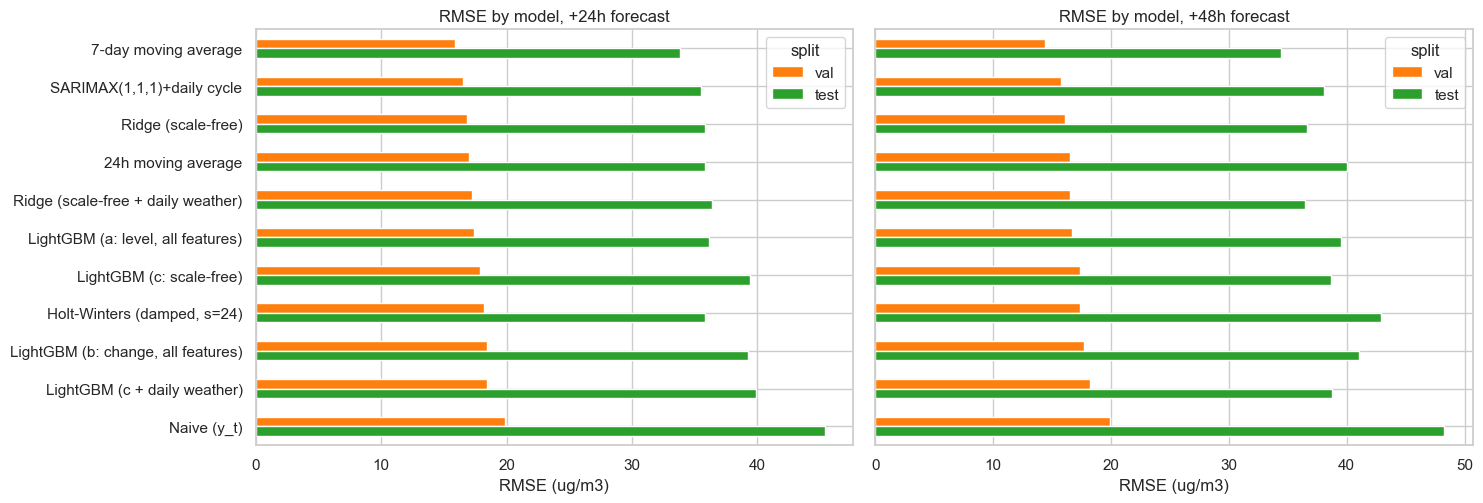

In [124]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(15, 5.2), sharey=True)
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    d = res[res.horizon == f"+{h}h"].pivot(index="model", columns="split", values="RMSE")[["val", "test"]].sort_values("val")
    d.plot.barh(ax=ax, color=["tab:orange", "tab:green"]); ax.invert_yaxis()
    ax.set_title(f"RMSE by model, +{h}h forecast"); ax.set_xlabel("RMSE (ug/m3)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### What do the daily weather features add? (ablation)
Same model, same inputs, with and without the three daily-weather columns. A negative change means weather helped.

In [125]:
pairs = [("LightGBM (c: scale-free)", "LightGBM (c + daily weather)"), ("Ridge (scale-free)", "Ridge (scale-free + daily weather)")]
rows = []
for a, b in pairs:
    for h in HORIZONS:
        for sp in ["val", "test"]:
            ra = res[(res.model == a) & (res.horizon == f"+{h}h") & (res.split == sp)]["RMSE"].iloc[0]
            rb = res[(res.model == b) & (res.horizon == f"+{h}h") & (res.split == sp)]["RMSE"].iloc[0]
            rows.append({"model": a.split(" (")[0], "horizon": f"+{h}h", "split": sp, "RMSE_without": ra, "RMSE_with_weather": rb, "change": rb - ra})
display(pd.DataFrame(rows).round(2).set_index(["model", "horizon", "split"]))

RMSE_without  RMSE_with_weather  change
model    horizon split                                         
LightGBM +24h    val           17.44              18.22    0.77
                 test          36.15              35.82   -0.33
         +48h    val           17.37              18.25    0.88
                 test          38.63              38.74    0.11
Ridge    +24h    val           16.88              16.99    0.12
                 test          35.81              35.79   -0.01
         +48h    val           16.10              16.56    0.46
                 test          36.64              36.50   -0.14

### How much can we trust the test numbers?
The test window is a few weeks long and consecutive hours are strongly correlated, so a plain RMSE is a noisy point estimate. A **moving-block bootstrap** (24 h blocks) resamples the test errors to give a rough 95% interval. Where intervals overlap, the ranking of models is not reliable.

In [126]:
def block_ci(err, block=24, n_boot=400, seed=0):
    e2 = np.asarray(err, dtype=float) ** 2
    n = len(e2); nb = int(np.ceil(n / block)); rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        starts = rng.integers(0, n - block + 1, size=nb)
        out.append(np.sqrt(np.concatenate([e2[s:s + block] for s in starts])[:n].mean()))
    return np.percentile(out, [2.5, 97.5])

rows = []
for h in HORIZONS:
    ix = split_idx(h, "test"); yt = actual(h, ix)
    for name, p in preds[h].items():
        err = (yt - p.loc[ix]).values
        lo, hi = block_ci(err)
        rows.append({"horizon": f"+{h}h", "model": name, "test_RMSE": np.sqrt((err ** 2).mean()), "CI95_low": lo, "CI95_high": hi})
ci = pd.DataFrame(rows).round(1)
display(ci.sort_values(["horizon", "test_RMSE"]).set_index(["horizon", "model"]))

test_RMSE  CI95_low  CI95_high
horizon model                                                             
+24h    7-day moving average                     33.8      23.1       46.1
        SARIMAX(1,1,1)+daily cycle               35.5      26.1       48.0
        LightGBM (c + daily weather)             35.8      23.2       49.6
        Ridge (scale-free)                       35.8      24.3       48.9
        Ridge (scale-free + daily weather)       35.8      24.5       48.9
        LightGBM (c: scale-free)                 36.1      23.7       49.7
        24h moving average                       36.4      27.4       48.7
        LightGBM (b: change, all features)       39.2      24.9       52.6
        Holt-Winters (damped, s=24)              39.4      27.9       51.7
        LightGBM (a: level, all features)        39.9      26.0       53.9
        Naive (y_t)                              45.4      31.1       60.2
+48h    7-day moving average                     34.4      24.4       47.7
        Ridge (scale-free + daily weather)       36.5      25.6       50.9
        Ridge (scale-free)                       36.6      25.6       51.1
        SARIMAX(1,1,1)+daily cycle               38.1      28.5       51.8
        LightGBM (c: scale-free)                 38.6      26.7       54.3
        LightGBM (c + daily weather)             38.7      25.7       54.1
        LightGBM (a: level, all features)        39.5      25.3       54.5
        24h moving average                       40.1      30.0       54.0
        LightGBM (b: change, all features)       41.1      27.8       55.6
        Holt-Winters (damped, s=24)              42.9      33.5       55.6
        Naive (y_t)                              48.3      37.0       61.6

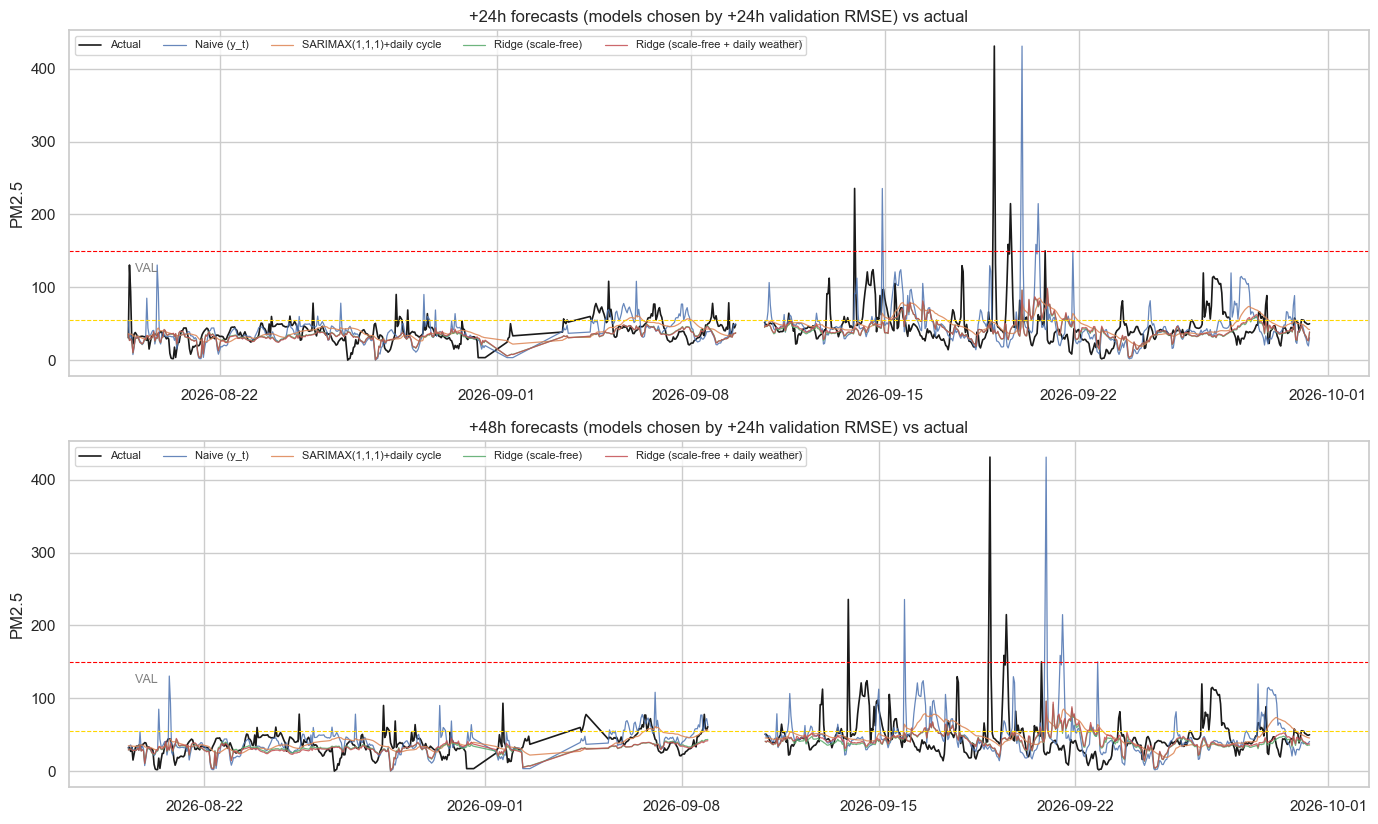

In [127]:
# Forecast vs actual (x-axis = the time being forecast); val and test windows drawn separately
show_models = ["Naive (y_t)"] + list(res[(res.horizon == f"+{HORIZONS[0]}h") & (res.split == "val") & ~res.model.isin(["Naive (y_t)", "24h moving average", "7-day moving average"])]
                                      .sort_values("RMSE").model[:3])
fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(14, 4.2 * len(HORIZONS)))
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    for k, sp in enumerate(["val", "test"]):
        ix = split_idx(h, sp); tt = ix + h * H
        ax.plot(tt, actual(h, ix).values, color="k", lw=1.2, label="Actual" if k == 0 else None)
        for j, name in enumerate(show_models):
            ax.plot(tt, preds[h][name].loc[ix].values, lw=0.9, alpha=0.85, color=f"C{j}", label=name if k == 0 else None)
        ax.text(tt[0], ax.get_ylim()[1] * 0.97, "  " + sp.upper(), va="top", fontsize=9, color="grey")
    ax.axhline(EVENT_THR, color="gold", ls="--", lw=0.8); ax.axhline(HIGH_THR, color="red", ls="--", lw=0.8)
    ax.set_title(f"+{h}h forecasts (models chosen by +{HORIZONS[0]}h validation RMSE) vs actual"); ax.set_ylabel("PM2.5")
    ax.legend(ncol=5, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

### Haze-event alerts
A forecast above the threshold counts as an alert, with no threshold tuning. First the NEA "Elevated" edge (55 ug/m3, the haze-event definition used here), then the "High" edge (150). Check `actual_events`: with few real events, precision and recall are only indicative.

In [128]:
def alerts(h, sp, thr):
    ix = split_idx(h, sp); truth = actual(h, ix) > thr; out = []
    for name, p in preds[h].items():
        pr = p.loc[ix] > thr
        tp, fp, fn = int((pr & truth).sum()), int((pr & ~truth).sum()), int((~pr & truth).sum())
        out.append({"horizon": f"+{h}h", "split": sp, "model": name, "actual_events": int(truth.sum()), "TP": tp, "FP": fp, "FN": fn,
                    "precision": round(tp / (tp + fp), 2) if tp + fp else np.nan,
                    "recall": round(tp / (tp + fn), 2) if tp + fn else np.nan})
    return out

for thr in (EVENT_THR, HIGH_THR):
    print(f"Alerts at PM2.5 > {thr} ug/m3 (test set only shown; validation in the full table below)")
    tbl = pd.DataFrame([r for h in HORIZONS for sp in ["val", "test"] for r in alerts(h, sp, thr)])
    display(tbl[tbl.split == "test"].drop(columns="split").set_index(["horizon", "model"]))
    if thr == EVENT_THR:
        alert_tbl_val = tbl[tbl.split == "val"]

Alerts at PM2.5 > 55 ug/m3 (test set only shown; validation in the full table below)


actual_events  TP   FP   FN  precision  recall
horizon model                                                                             
+24h    Naive (y_t)                                   102  20   87   82       0.19    0.20
        24h moving average                            102  27   92   75       0.23    0.26
        7-day moving average                          102   6   77   96       0.07    0.06
        SARIMAX(1,1,1)+daily cycle                    102  28  104   74       0.21    0.27
        Holt-Winters (damped, s=24)                   102  30  106   72       0.22    0.29
        LightGBM (a: level, all features)             102   0    0  102        NaN    0.00
        LightGBM (b: change, all features)            102   4    5   98       0.44    0.04
        LightGBM (c: scale-free)                      102  11   43   91       0.20    0.11
        LightGBM (c + daily weather)                  102   9   32   93       0.22    0.09
        Ridge (scale-free)                            102  12   56   90       0.18    0.12
        Ridge (scale-free + daily weather)            102  13   61   89       0.18    0.13
+48h    Naive (y_t)                                   102  20   81   82       0.20    0.20
        24h moving average                            102   9  110   93       0.08    0.09
        7-day moving average                          102   7   76   95       0.08    0.07
        SARIMAX(1,1,1)+daily cycle                    102   8  122   94       0.06    0.08
        Holt-Winters (damped, s=24)                   102  26  101   76       0.20    0.25
        LightGBM (a: level, all features)             102   0    0  102        NaN    0.00
        LightGBM (b: change, all features)            102   1    9  101       0.10    0.01
        LightGBM (c: scale-free)                      102   6   48   96       0.11    0.06
        LightGBM (c + daily weather)                  102   2   33  100       0.06    0.02
        Ridge (scale-free)                            102   2   46  100       0.04    0.02
        Ridge (scale-free + daily weather)            102   2   50  100       0.04    0.02

Alerts at PM2.5 > 150 ug/m3 (test set only shown; validation in the full table below)


actual_events  TP  FP  FN  precision  recall
horizon model                                                                           
+24h    Naive (y_t)                                     6   0   6   6        0.0     0.0
        24h moving average                              6   0   0   6        NaN     0.0
        7-day moving average                            6   0   0   6        NaN     0.0
        SARIMAX(1,1,1)+daily cycle                      6   0   0   6        NaN     0.0
        Holt-Winters (damped, s=24)                     6   0   2   6        0.0     0.0
        LightGBM (a: level, all features)               6   0   0   6        NaN     0.0
        LightGBM (b: change, all features)              6   0   2   6        0.0     0.0
        LightGBM (c: scale-free)                        6   0   0   6        NaN     0.0
        LightGBM (c + daily weather)                    6   0   0   6        NaN     0.0
        Ridge (scale-free)                              6   0   0   6        NaN     0.0
        Ridge (scale-free + daily weather)              6   0   0   6        NaN     0.0
+48h    Naive (y_t)                                     6   0   6   6        0.0     0.0
        24h moving average                              6   0   0   6        NaN     0.0
        7-day moving average                            6   0   0   6        NaN     0.0
        SARIMAX(1,1,1)+daily cycle                      6   0   0   6        NaN     0.0
        Holt-Winters (damped, s=24)                     6   0   2   6        0.0     0.0
        LightGBM (a: level, all features)               6   0   0   6        NaN     0.0
        LightGBM (b: change, all features)              6   0   1   6        0.0     0.0
        LightGBM (c: scale-free)                        6   0   0   6        NaN     0.0
        LightGBM (c + daily weather)                    6   0   0   6        NaN     0.0
        Ridge (scale-free)                              6   0   0   6        NaN     0.0
        Ridge (scale-free + daily weather)              6   0   0   6        NaN     0.0

## Part 3 · 7. Shortlist for tuning (Phase 5)
The two strongest **non-baseline** models by mean validation RMSE across the two horizons. The test set plays no part in this choice.

In [129]:
BASELINES = ("Naive (y_t)", "24h moving average", "7-day moving average")
CANDIDATES = [m for m in preds[HORIZONS[0]] if m not in BASELINES]
val_rank = (res[(res.split == "val") & res.model.isin(CANDIDATES)].pivot_table(index="model", columns="horizon", values="RMSE"))
val_rank["mean_val_RMSE"] = val_rank.mean(axis=1)
val_rank = val_rank.sort_values("mean_val_RMSE").round(2)
display(val_rank)
TOP2 = list(val_rank.index[:2])
print("Shortlisted for Phase 5 tuning:", TOP2)

horizon,+24h,+48h,mean_val_RMSE
model,,,
"SARIMAX(1,1,1)+daily cycle",16.54,15.77,16.16
Ridge (scale-free),16.88,16.10,16.49
Ridge (scale-free + daily weather),16.99,16.56,16.78
LightGBM (c: scale-free),17.44,17.37,17.40
"LightGBM (a: level, all features)",18.48,16.65,17.57
"Holt-Winters (damped, s=24)",17.92,17.41,17.67
"LightGBM (b: change, all features)",18.44,17.71,18.08
LightGBM (c + daily weather),18.22,18.25,18.23


Shortlisted for Phase 5 tuning: ['SARIMAX(1,1,1)+daily cycle', 'Ridge (scale-free)']


## Reading these results (Phase 4)

**What the numbers say**
- Every non-naive model beats the naive forecast (y_t) by roughly 8-29% RMSE, so some structure is learnable.
- **No candidate beats the 7-day moving average on the test set** (+24h RMSE 33.8 vs 35.5-39.7; +48h 34.4 vs 36.5-42.9). On validation the 7-day average is also best at +24h and +48h except that SARIMAX is close.
- The 95% block-bootstrap intervals of the top models overlap heavily (e.g. +24h: 23-50), so the **ranking between models is not statistically reliable**. We cannot claim one model is better than another.
- Daily weather (rain, wind from Marina Barrage) does **not** give a consistent gain: RMSE changes are within about +/-0.9 µg/m3 and flip sign between validation and test.
- **Spike alerts are weak.** At >55 µg/m3 the best test recall is about 0.29 with precision about 0.22 (Holt-Winters, +24h); at >150 µg/m3 no model catches any of the 6 test hours. LightGBM (a) predicts no events at all because trees cannot go above values seen in training.

**Why**
- Training period (Apr-mid Aug) is calm (mean 20 µg/m3) while validation/test are hazier (38 / 49). Models learn "calm" behaviour and shrink toward it.
- Only 3 training hours exceed 150 µg/m3; learning spikes from so few examples is not possible.
- A sensor-only, single-site view sees a plume only after it arrives. Without upwind data (fire hotspots, wind direction) a 24-48 h warning is mostly guesswork.

**Shortlist for Phase 5 (by mean validation RMSE):** SARIMAX(1,1,1)+daily cycle and Ridge (scale-free). The shortlist is chosen on validation only; the 7-day moving average remains the benchmark to beat.

## Limitations (read before using any number above)

**Data**
1. **One sensor** (Marine Terrace, low-cost AirGradient, not calibrated against NEA reference monitors; humidity can bias optical PM2.5). Results describe this location only. No spatial features are possible.
2. **Coverage is 9 Apr - 30 Sep 2026.** The October haze peak is not in the data, so the most relevant episodes for the project theme are missing.
3. **Gaps:** one 17-day outage (28 Apr - 15 May, 407 h), plus five ~24 h gaps at each month boundary (exports ended at 08:00 UTC on the last day) and several short gaps. Short gaps (<=6 h) are forward-filled; longer ones stay missing. The month-boundary gaps can be recovered by re-exporting with the end date set to the 1st of the next month.
4. 121 zero/invalid sensor values were set to missing (24 exact-zero PM2.5 readings look like dropouts).
5. **Weather is daily only** (Marina Barrage). No wind direction, no hourly resolution, and all three temperature columns are empty. Because a day's summary is only known after the day ends, weather features use days up to D-1 and cannot describe today's rain or wind.
6. No fire-hotspot, satellite or upwind-station data, which are the real drivers of transboundary haze.

**Modelling**
7. **Regime shift:** train mean 20, validation 38, test 49 µg/m3. Metrics on validation and test are not comparable to each other.
8. **Very few spike hours:** 10 hours above 150 in the whole file (3 train, 0 validation, 6 test, and 5 of those 6 test hours belong to a single day, 18-19 Sep). Spike metrics are anecdotal.
9. Hourly rows are strongly autocorrelated, so the effective sample size is far smaller than the row count; bootstrap uses 24 h blocks to account for this, but intervals are still approximate.
10. Chronological 70/15/15 split with purging (rows whose target falls in the next period are dropped). No month feature is used, since the training period contains no October-like months.
11. Classical models (SARIMAX, Holt-Winters) use data after the 17-day outage with up to 30 h of interpolation; parameters are fitted once on train and not refit per origin.
12. The scale-free features and log-ratio target were designed after seeing validation behaviour, so validation scores are slightly optimistic for those variants.
13. Weather correlations (e.g. wind vs next-day PM2.5, about +0.24) are associations on a small sample and are not causal.
14. NEA health advisories use 24-h PSI; this notebook uses the 1-hour PM2.5 bands only.

---
# Part 4: Hyperparameter Tuning, Evaluation and Final Model Selection (Phase 5)

**Protocol**
- **Models tuned:** the two strongest non-baseline models from the Part 3 shortlist (`TOP2`), chosen on validation RMSE only.
- **Data used for tuning:** the *development set* = training + validation rows. Test rows are never used for tuning, feature choice or model selection.
- **Validation design:** expanding-window time-series CV. Each fold trains on the past and is validated on the next 7 days. A training row is allowed only if its label time (t + h) is before the fold starts, so no label overlaps a validation block.
- **Metric:** mean RMSE (µg/m³) over the folds, the same primary metric as Part 3.
- **Benchmark:** the best moving-average baseline, because Part 3 showed that no candidate beat the 7-day moving average.
- **Final step:** choices are frozen by a rule that uses CV results only, then each configuration is refit on the development set and scored **once** on the test set.
- **Terminology:** in all Part 4 tables, "default" means the *initial configuration* fixed in Part 3 (for example Ridge `alpha=100`, SARIMAX(1,1,1) with one daily harmonic), not the libraries' built-in defaults. "Tuned" means the best configuration found by the cross-validated search.

## Part 4 · 0. Setup
Why this cell: it loads the search tools and checks that the shortlisted models belong to families this tuning code supports (SARIMAX and Ridge). If another family were shortlisted it would need its own routine.

In [130]:
def family(name):
    return "sarimax" if name.startswith("SARIMAX") else "ridge" if name.startswith("Ridge") else None

assert all(family(m) for m in TOP2), f"Unsupported model in TOP2: {TOP2} (send me the list and I will adapt the code)"
print("Models to tune:", TOP2)

Models to tune: ['SARIMAX(1,1,1)+daily cycle', 'Ridge (scale-free)']


## Part 4 · 1. Development set and expanding-window folds
**Why a custom fold builder instead of `TimeSeriesSplit`:** our modelling table has holes (the 17-day sensor outage and month-boundary gaps), so "skip h rows" is not the same as "skip h hours". Here, a training row is kept only if `index + h hours < start of the validation block`, which gives the correct purge at any gap.

**Why 4 folds of 168 h (7 days):** one week contains every weekday and about 7 daily cycles, so each fold score is not dominated by a single day. Four folds cover the last 28 days of the development set, which is mostly the validation period. That period is hazier and closer to the test regime than the calm April-August training period, so tuning is steered toward the conditions the model will face.

**Why score every 3rd forecast origin (`ORIGIN_STEP = 3`):** consecutive hourly origins are almost identical (lag-1 autocorrelation is about 0.97), so the subsample loses little information but makes SARIMAX tuning about 3 times faster. All models and baselines are scored on exactly the same origins.

In [131]:
N_FOLDS, FOLD_HOURS, ORIGIN_STEP = 4, 168, 3

def dev_index(h):
    """Train + validation rows (and the purged rows between them) whose labels end before the test period."""
    last_val = split_idx(h, "val").max()
    return data.index[(data.index <= last_val) & data[f"target_h{h}"].notna()]

def make_folds(h):
    dev = dev_index(h)
    ev_all = dev[-N_FOLDS * FOLD_HOURS:]
    folds = []
    for k in range(N_FOLDS):
        blk = ev_all[k * FOLD_HOURS:(k + 1) * FOLD_HOURS]
        tr = dev[dev + h * H < blk.min()]              # label time of every training row is before the block
        assert len(tr) > 200 and tr.max() + h * H < blk.min()
        folds.append((tr, blk[::ORIGIN_STEP]))
    assert dev.max() + h * H < split_idx(h, "test").min(), "dev labels reach into the test period"
    return folds

FOLDS = {h: make_folds(h) for h in HORIZONS}
rows = []
for h in HORIZONS:
    for k, (tr, ev) in enumerate(FOLDS[h], 1):
        rows.append({"horizon": f"+{h}h", "fold": k, "train_rows": len(tr), "train_to": tr.max(),
                     "val_from": ev.min(), "val_to": ev.max(), "origins_scored": len(ev),
                     "mean_target": data.loc[ev, f"target_h{h}"].mean()})
display(pd.DataFrame(rows).round(1))
print("Dev-set rows:", {f"+{h}h": len(dev_index(h)) for h in HORIZONS})

,horizon,fold,train_rows,train_to,val_from,val_to,origins_scored,mean_target
0,+24h,1,1962,2026-08-07 09:00:00,2026-08-08 10:00:00,2026-08-15 07:00:00,56,37.1
1,+24h,2,2130,2026-08-14 09:00:00,2026-08-15 10:00:00,2026-08-22 07:00:00,56,32.4
2,+24h,3,2298,2026-08-21 09:00:00,2026-08-22 10:00:00,2026-08-29 07:00:00,56,37.5
3,+24h,4,2466,2026-08-28 09:00:00,2026-08-29 10:00:00,2026-09-08 13:00:00,56,43.5
4,+48h,1,1873,2026-08-04 16:00:00,2026-08-06 17:00:00,2026-08-13 14:00:00,56,37.0
5,+48h,2,2041,2026-08-11 16:00:00,2026-08-13 17:00:00,2026-08-20 14:00:00,56,32.2
6,+48h,3,2209,2026-08-18 16:00:00,2026-08-20 17:00:00,2026-08-27 14:00:00,56,35.4
7,+48h,4,2377,2026-08-25 16:00:00,2026-08-27 17:00:00,2026-09-06 20:00:00,56,37.0


Dev-set rows: {'+24h': 2658, '+48h': 2593}


## Part 4 · 2. Prediction functions, CV engine and reference scores
**Why custom code instead of `GridSearchCV`:** (1) Ridge predicts the **log of the ratio** y(t+h)/y(t) and must be converted back to PM2.5 before scoring, so the RMSE is in µg/m³; (2) SARIMAX is *fitted once on the past and then applied to a 14-day window before each origin*, which is not the standard fit/predict interface. One shared loop applies the same folds and the same metric to every model, which keeps the comparison fair.

**Hyperparameters that will be tuned**
- *SARIMAX:* the autoregressive order `p`, the moving-average order `q`, and `K`, the number of daily-cycle harmonics (sin/cos pairs) used as exogenous inputs. `d = 1` stays fixed because PM2.5 is not stationary in level.
- *Ridge:* `alpha` (shrinkage strength), `half_life` (recency weighting: a training row's weight halves every `half_life` hours, aimed at the calm-to-hazy regime shift; `None` = equal weights) and `features` (scale-free inputs with or without the daily-weather inputs, which turns the Part 3 ablation into a tuned choice).

**Reference scores:** the Part 3 "default" settings and the three baselines are scored on the same folds. These Part 3 settings are our *initial configuration*, not library defaults (for example `alpha=100`).

In [132]:
BASE_COL = {"Naive (y_t)": "pm25_now", "24h moving average": "pm25_rollmean24", "7-day moving average": "pm25_rollmean168"}
FEATSETS = {"scale-free": XR, "scale-free + weather": XRW}

def default_params(name):
    if family(name) == "sarimax":
        return {"p": 1, "q": 1, "K": 1}                                  # = SARIMAX(1,1,1) + one daily harmonic (Part 3)
    return {"alpha": 100.0, "half_life": None,
            "features": "scale-free + weather" if "weather" in name else "scale-free"}

def recency_weights(ix, half_life):
    if half_life is None:
        return None
    age = (ix.max() - ix) / pd.Timedelta(hours=1)
    return np.asarray(0.5 ** (age / half_life))

def ridge_predict(p, h, tr_ix, ev_ix):
    X = FEATSETS[p["features"]]
    ytr, now_tr, now_ev = data.loc[tr_ix, f"target_h{h}"], data.loc[tr_ix, "pm25_now"], data.loc[ev_ix, "pm25_now"]
    est = make_pipeline(StandardScaler(), Ridge(alpha=p["alpha"]))
    w = recency_weights(tr_ix, p["half_life"])
    est.fit(X.loc[tr_ix], np.log(ytr / now_tr), **({} if w is None else {"ridge__sample_weight": w}))
    raw = pd.Series(est.predict(X.loc[ev_ix]), index=ev_ix).clip(-1.5, 1.5)
    return (now_ev * np.exp(raw)).clip(lower=0), est

def hour_exog_k(idx, K):
    hr = np.asarray(idx.hour); cols = {}
    for k in range(1, K + 1):
        cols[f"sin{k}"], cols[f"cos{k}"] = np.sin(2 * np.pi * k * hr / 24), np.cos(2 * np.pi * k * hr / 24)
    return pd.DataFrame(cols, index=idx)

def sarimax_predict(p, h, train_end_label, ev_ix):
    y_fit = y_cls.loc[start_cls:train_end_label].ffill().bfill()
    base = SARIMAX(y_fit, exog=hour_exog_k(y_fit.index, p["K"]), order=(p["p"], 1, p["q"])).fit(disp=False)
    out = {}
    for t in ev_ix:
        w = window_at(t)                                              # preceding 14 days, as in Part 3
        r = base.apply(w, exog=hour_exog_k(w.index, p["K"]), refit=False)
        fut = pd.date_range(t + H, periods=h, freq="h")
        out[t] = float(r.forecast(steps=h, exog=hour_exog_k(fut, p["K"])).iloc[-1])
    return pd.Series(out).clip(lower=0), base

def rmse(yt, p):
    return float(np.sqrt(((yt - p) ** 2).mean()))

def cv_score(fam, p, h):
    errs = []
    for tr_ix, ev_ix in FOLDS[h]:
        try:
            pred = ridge_predict(p, h, tr_ix, ev_ix)[0] if fam == "ridge" else sarimax_predict(p, h, tr_ix.max() + h * H, ev_ix)[0]
        except Exception as e:                                         # a failed fit must not stop the search
            print("   fit failed:", p, type(e).__name__); return np.inf, np.nan
        errs.append(rmse(data.loc[ev_ix, f"target_h{h}"], pred))
    return float(np.mean(errs)), float(np.std(errs))

ref, t0 = [], time.time()
for h in HORIZONS:
    for b, col in BASE_COL.items():
        errs = [rmse(data.loc[ev, f"target_h{h}"], data.loc[ev, col]) for _, ev in FOLDS[h]]
        ref.append({"horizon": f"+{h}h", "model": b, "cv_rmse": np.mean(errs), "cv_std": np.std(errs)})
    for name in TOP2:
        m, s = cv_score(family(name), default_params(name), h)
        ref.append({"horizon": f"+{h}h", "model": f"{name} [default]", "cv_rmse": m, "cv_std": s})
ref = pd.DataFrame(ref)
display(ref.round(2).set_index(["horizon", "model"]))
print(f"{time.time() - t0:.0f}s for the reference scores (use this to judge the search time below)")

cv_rmse  cv_std
horizon model                                                
+24h    Naive (y_t)                             17.04    3.99
        24h moving average                      14.86    3.75
        7-day moving average                    14.16    3.55
        SARIMAX(1,1,1)+daily cycle [default]    14.29    3.66
        Ridge (scale-free) [default]            15.13    3.02
+48h    Naive (y_t)                             15.31    2.45
        24h moving average                      13.61    2.60
        7-day moving average                    12.60    2.14
        SARIMAX(1,1,1)+daily cycle [default]    13.09    2.27
        Ridge (scale-free) [default]            14.18    2.26

6s for the reference scores (use this to judge the search time below)


## Part 4 · 3. Search spaces and search method
**Why full grid search for both models:** each space is small enough to evaluate completely, which is exhaustive, easy to explain, and needs no random seed.
- *SARIMAX* (2 × 2 × 2 = 8 candidates): orders 1-2 for `p` and `q` are the usual range for hourly series with strong persistence; higher orders would overfit a few thousand points and take much longer to fit. `K` in {1, 2} tests whether a second harmonic captures a non-sinusoidal daily shape.
- *Ridge* (8 × 4 × 2 = 64 candidates): `alpha` spans 0.1 to 3000 on a log-like scale because the right amount of shrinkage can differ by orders of magnitude. `half_life` in {none, 120, 336, 720 h} ranges from "forget quickly" (5 days) to "almost equal weights". Ridge fits take milliseconds, so the larger grid is cheap.
- One search is run **per horizon**, because the +24h and +48h problems have different label timing and the best settings need not be the same.

In [133]:
SPACES = {"sarimax": {"p": [1, 2], "q": [1, 2], "K": [1, 2]},
          "ridge":   {"alpha": [0.1, 1, 10, 30, 100, 300, 1000, 3000], "half_life": [None, 120, 336, 720],
                      "features": list(FEATSETS)}}
for fam in sorted({family(m) for m in TOP2}):
    print(f"{fam:8s} {SPACES[fam]}  -> {len(ParameterGrid(SPACES[fam]))} candidates per horizon")

ridge    {'alpha': [0.1, 1, 10, 30, 100, 300, 1000, 3000], 'half_life': [None, 120, 336, 720], 'features': ['scale-free', 'scale-free + weather']}  -> 64 candidates per horizon
sarimax  {'p': [1, 2], 'q': [1, 2], 'K': [1, 2]}  -> 8 candidates per horizon


## Part 4 · 4. Run the search
Each candidate is scored by its mean RMSE across the 4 folds; the standard deviation across folds is kept to show how stable the score is. The test set is not involved. SARIMAX is the slow part (each candidate means 4 fits plus one filtering pass per scored origin), so progress is printed.

In [134]:
tuning, best = {}, {}
for name in TOP2:
    fam = family(name)
    for h in HORIZONS:
        t0, rows = time.time(), []
        for p in ParameterGrid(SPACES[fam]):
            m, s = cv_score(fam, p, h)
            rows.append({"params": p, "cv_rmse": m, "cv_std": s})
        df = pd.DataFrame(rows).sort_values("cv_rmse").reset_index(drop=True)
        tuning[(name, h)], best[(name, h)] = df, df.loc[0, "params"]
        print(f"{name} +{h}h: best CV RMSE {df.loc[0, 'cv_rmse']:.2f} with {best[(name, h)]}  ({time.time() - t0:.0f}s)")

SARIMAX(1,1,1)+daily cycle +24h: best CV RMSE 14.29 with {'K': 1, 'p': 2, 'q': 1}  (42s)
SARIMAX(1,1,1)+daily cycle +48h: best CV RMSE 13.09 with {'K': 1, 'p': 1, 'q': 1}  (44s)
Ridge (scale-free) +24h: best CV RMSE 14.68 with {'alpha': 10, 'features': 'scale-free + weather', 'half_life': 336}  (2s)
Ridge (scale-free) +48h: best CV RMSE 13.39 with {'alpha': 1, 'features': 'scale-free', 'half_life': 336}  (1s)


## Part 4 · 5. Default vs tuned: cross-validation comparison
This is the like-for-like comparison: both configurations are scored on the **same folds, origins and metric**. `improvement_%` is positive if tuning lowered RMSE.

**Read with care:** the "tuned" score is the best of many candidates, so it is optimistically biased (winner's curse). Only the untouched test set in Step 8 can confirm a real gain. A small or zero gain is a valid result: it means the initial configuration was already adequate, or that the data are too limited for tuning to help.

In [135]:
rows = []
for name in TOP2:
    for h in HORIZONS:
        d = ref[(ref.horizon == f"+{h}h") & (ref.model == f"{name} [default]")].iloc[0]
        t = tuning[(name, h)].iloc[0]
        rows.append({"model": name, "horizon": f"+{h}h", "default_cv_rmse": d.cv_rmse, "tuned_cv_rmse": t.cv_rmse,
                     "improvement_%": (1 - t.cv_rmse / d.cv_rmse) * 100, "tuned_cv_std": t.cv_std, "best_params": best[(name, h)]})
summary = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 120, "display.width", 250):
    display(summary.round(2).set_index(["model", "horizon"]))

default_cv_rmse  tuned_cv_rmse  improvement_%  tuned_cv_std                                                          best_params
model                      horizon                                                                                                                                  
SARIMAX(1,1,1)+daily cycle +24h               14.29          14.29           0.02          3.66                                             {'K': 1, 'p': 2, 'q': 1}
                           +48h               13.09          13.09           0.00          2.27                                             {'K': 1, 'p': 1, 'q': 1}
Ridge (scale-free)         +24h               15.13          14.68           2.99          3.47  {'alpha': 10, 'features': 'scale-free + weather', 'half_life': 336}
                           +48h               14.18          13.39           5.53          2.42             {'alpha': 1, 'features': 'scale-free', 'half_life': 336}

## Part 4 · 6. Search diagnostics
The best parameter set alone is not enough evidence. The plots show every candidate's CV RMSE (sorted) against the default configuration and the **best moving-average baseline**. If many candidates sit close together, the model is insensitive to its hyperparameters and the exact "best" setting is not important. If all candidates sit above the baseline line, tuning cannot rescue the model. For Ridge, the table also shows how CV RMSE changes with `alpha` and `half_life` (best feature set for each cell).

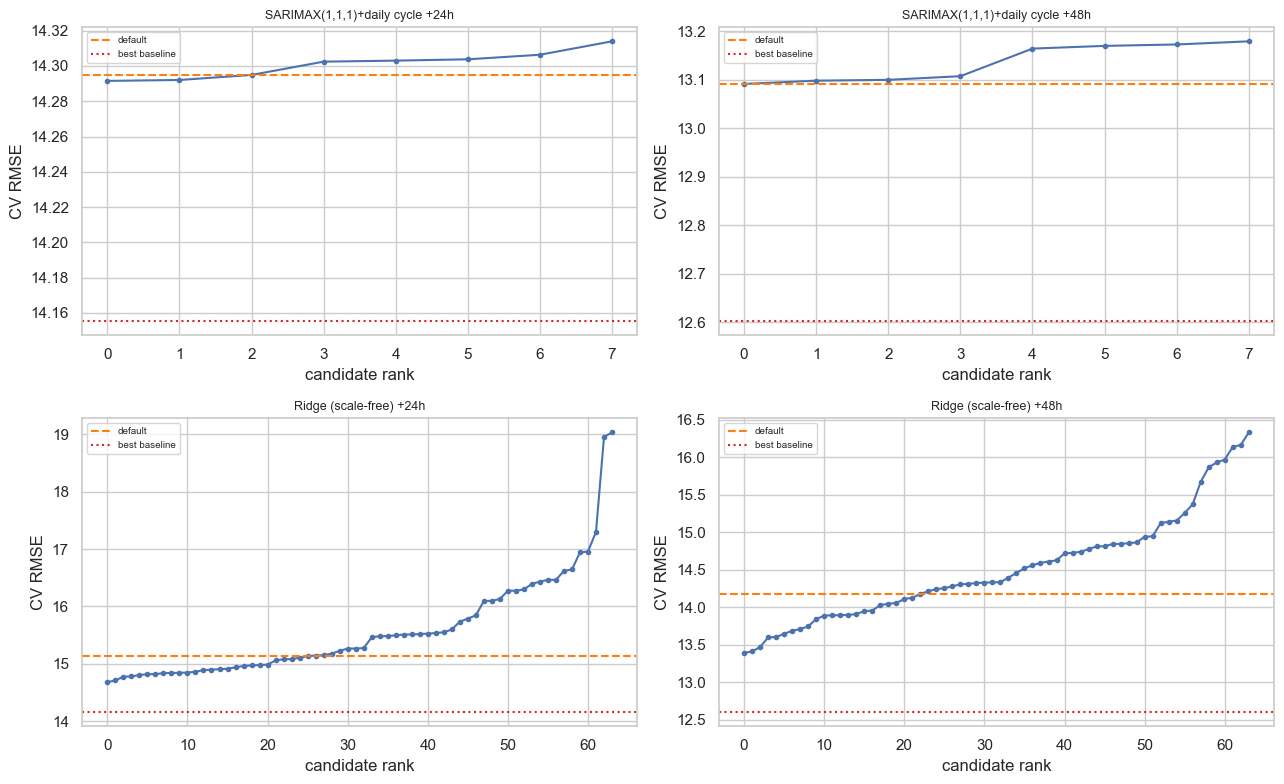

Ridge (scale-free) +24h: CV RMSE by alpha (rows) and half_life in hours (columns)


half_life,120,336,720,none
alpha,,,,
0.1,16.46,14.78,15.27,16.13
1.0,16.30,14.71,15.23,16.10
10.0,15.79,14.68,14.98,15.84
30.0,15.14,14.81,14.86,15.51
100.0,14.89,14.78,14.84,15.13
300.0,15.50,14.84,14.84,14.97
1000.0,16.43,15.46,14.96,14.91
3000.0,16.94,16.27,15.52,14.94


Ridge (scale-free) +48h: CV RMSE by alpha (rows) and half_life in hours (columns)


half_life,120,336,720,none
alpha,,,,
0.1,14.95,13.47,13.95,15.16
1.0,14.81,13.39,13.89,15.12
10.0,14.84,13.41,13.65,14.85
30.0,14.33,13.60,13.60,14.52
100.0,14.03,13.71,13.69,14.18
300.0,14.24,13.84,13.75,14.05
1000.0,14.56,14.21,13.89,13.96
3000.0,14.85,14.72,14.31,13.90


In [136]:
fig, axes = plt.subplots(len(TOP2), len(HORIZONS), figsize=(13, 4 * len(TOP2)), squeeze=False)
for i, name in enumerate(TOP2):
    for j, h in enumerate(HORIZONS):
        ax, df = axes[i][j], tuning[(name, h)]
        base = ref[(ref.horizon == f"+{h}h") & ref.model.isin(BASELINES)].cv_rmse.min()
        dflt = ref[(ref.horizon == f"+{h}h") & (ref.model == f"{name} [default]")].cv_rmse.iloc[0]
        ax.plot(range(len(df)), df["cv_rmse"], "o-", ms=3)
        ax.axhline(dflt, color="tab:orange", ls="--", label="default"); ax.axhline(base, color="tab:red", ls=":", label="best baseline")
        ax.set_title(f"{name[:30]} +{h}h", fontsize=9); ax.set_xlabel("candidate rank"); ax.set_ylabel("CV RMSE"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

for name in [m for m in TOP2 if family(m) == "ridge"]:
    for h in HORIZONS:
        df = tuning[(name, h)]
        exp = pd.DataFrame(list(df["params"])).assign(cv=df["cv_rmse"].values)
        exp["half_life"] = exp["half_life"].apply(lambda v: "none" if pd.isna(v) else int(v))
        print(f"{name} +{h}h: CV RMSE by alpha (rows) and half_life in hours (columns)")
        display(exp.pivot_table(index="alpha", columns="half_life", values="cv", aggfunc="min").round(2))

## Part 4 · 7. Final model selection (decided before looking at the test set)
**Why a pre-declared rule:** to avoid choosing a model after seeing test scores, the rule uses **CV results only**.
- Take the tuned model with the lowest mean CV RMSE over both horizons.
- Recommend it **only if it beats the best moving-average baseline by at least `MARGIN` (5%)** in CV. Otherwise the simple baseline is the honest operational choice: it needs no training, cannot overfit, and is trivially explainable to NEA. The brief explicitly accepts that a simpler model may remain preferable.
- The test results in Step 8 are then used only to *check* that this decision is not contradicted.

In [137]:
MARGIN = 0.05
base_cv = ref[ref.model.isin(BASELINES)].groupby("model")["cv_rmse"].mean().sort_values()
tuned_cv = summary.groupby("model")["tuned_cv_rmse"].mean().sort_values()
best_base, best_model = base_cv.index[0], tuned_cv.index[0]
beats = tuned_cv.iloc[0] < (1 - MARGIN) * base_cv.iloc[0]
print("Mean CV RMSE, baselines:"); display(base_cv.round(2).to_frame("cv_rmse"))
print("Mean CV RMSE, tuned models:"); display(tuned_cv.round(2).to_frame("cv_rmse"))
print(f"Best tuned model: {best_model} | best baseline: {best_base}")
print(f"Tuned model at least {MARGIN:.0%} better than the baseline in CV?  {beats}")
FINAL = best_model if beats else best_base
print("=> Recommended operational forecaster:", FINAL)

Mean CV RMSE, baselines:


,cv_rmse
model,
7-day moving average,13.38
24h moving average,14.24
Naive (y_t),16.17


Mean CV RMSE, tuned models:


,cv_rmse
model,
"SARIMAX(1,1,1)+daily cycle",13.69
Ridge (scale-free),14.04


Best tuned model: SARIMAX(1,1,1)+daily cycle | best baseline: 7-day moving average
Tuned model at least 5% better than the baseline in CV?  False
=> Recommended operational forecaster: 7-day moving average


## Part 4 · 8. Final evaluation on the test set (used once)
Both the default and the tuned configurations are **refit on the development set (train + validation)** and then scored once on the untouched test rows. Refitting the default too keeps the comparison fair; its numbers can differ from Part 3, where it was fit on the training rows only.

**Metrics:** RMSE and MAE (primary), MAPE (valid because PM2.5 is never zero after cleaning), and skill vs naive (positive = better). The 95% interval is the 24-hour moving-block bootstrap from Part 3, which respects autocorrelation. Overlapping intervals mean we cannot claim one model is truly better than another.

In [139]:
test_preds = {h: {} for h in HORIZONS}
for h in HORIZONS:
    te, dev = split_idx(h, "test"), dev_index(h)
    assert dev.max() + h * H < te.min()
    for b in BASELINES:
        test_preds[h][b] = preds[h][b].loc[te]
    for name in TOP2:
        fam = family(name)
        for label, p in [("default", default_params(name)), ("tuned", best[(name, h)])]:
            test_preds[h][f"{name} [{label}]"] = (ridge_predict(p, h, dev, te)[0] if fam == "ridge"
                                                  else sarimax_predict(p, h, dev.max() + h * H, te)[0])

rows = []
for h in HORIZONS:
    te = split_idx(h, "test"); yt = actual(h, te)
    for mname, p in test_preds[h].items():
        lo, hi = block_ci((yt - p).values)
        rows.append({"horizon": f"+{h}h", "model": mname, "n": len(te), **metrics(yt, p), "CI95_low": lo, "CI95_high": hi})
test_res = pd.DataFrame(rows)
nv = test_res[test_res.model == "Naive (y_t)"].set_index("horizon")["RMSE"]
test_res["skill_vs_naive"] = 1 - test_res["RMSE"] / test_res["horizon"].map(nv)
display(test_res.round(2).set_index(["horizon", "model"]))

n   RMSE    MAE  MAPE_%  CI95_low  CI95_high  skill_vs_naive
horizon model                                                                                               
+24h    Naive (y_t)                           473  45.35  27.34   73.03     31.14      60.16            0.00
        24h moving average                    473  36.38  22.84   62.84     27.38      48.71            0.20
        7-day moving average                  473  33.84  19.67   66.46     23.08      46.15            0.25
        SARIMAX(1,1,1)+daily cycle [default]  473  35.71  22.21   64.31     26.42      48.11            0.21
        SARIMAX(1,1,1)+daily cycle [tuned]    473  35.64  22.12   64.59     26.30      47.99            0.21
        Ridge (scale-free) [default]          473  35.70  21.11   59.30     24.33      48.72            0.21
        Ridge (scale-free) [tuned]            473  35.25  21.01   63.77     24.68      47.87            0.22
+48h    Naive (y_t)                           466  48.26  28.18   90.37     36.97      61.64            0.00
        24h moving average                    466  40.06  26.01   84.39     30.05      53.99            0.17
        7-day moving average                  466  34.43  20.36   72.32     24.40      47.72            0.29
        SARIMAX(1,1,1)+daily cycle [default]  466  38.64  24.63   83.37     29.09      52.44            0.20
        SARIMAX(1,1,1)+daily cycle [tuned]    466  38.64  24.63   83.37     29.09      52.44            0.20
        Ridge (scale-free) [default]          466  36.53  21.80   65.27     25.52      50.99            0.24
        Ridge (scale-free) [tuned]            466  37.97  23.41   71.08     27.73      51.78            0.21

## Part 4 · 9. Forecast and error diagnostics (test set)
Metrics hide *how* a model fails. The top row compares actual PM2.5 with the best baseline, the default and the tuned model of the best tuned family. The bottom row plots the residuals (actual minus forecast) of the **recommended forecaster** against the actual level. For an early-warning use case the key question is whether errors are largest exactly when PM2.5 is high (systematic under-forecasting), which would limit how far alerts can be trusted.

+24h mean residual when actual > 55: 43.3 (n=102); otherwise -11.7
+48h mean residual when actual > 55: 43.4 (n=102); otherwise -12.2


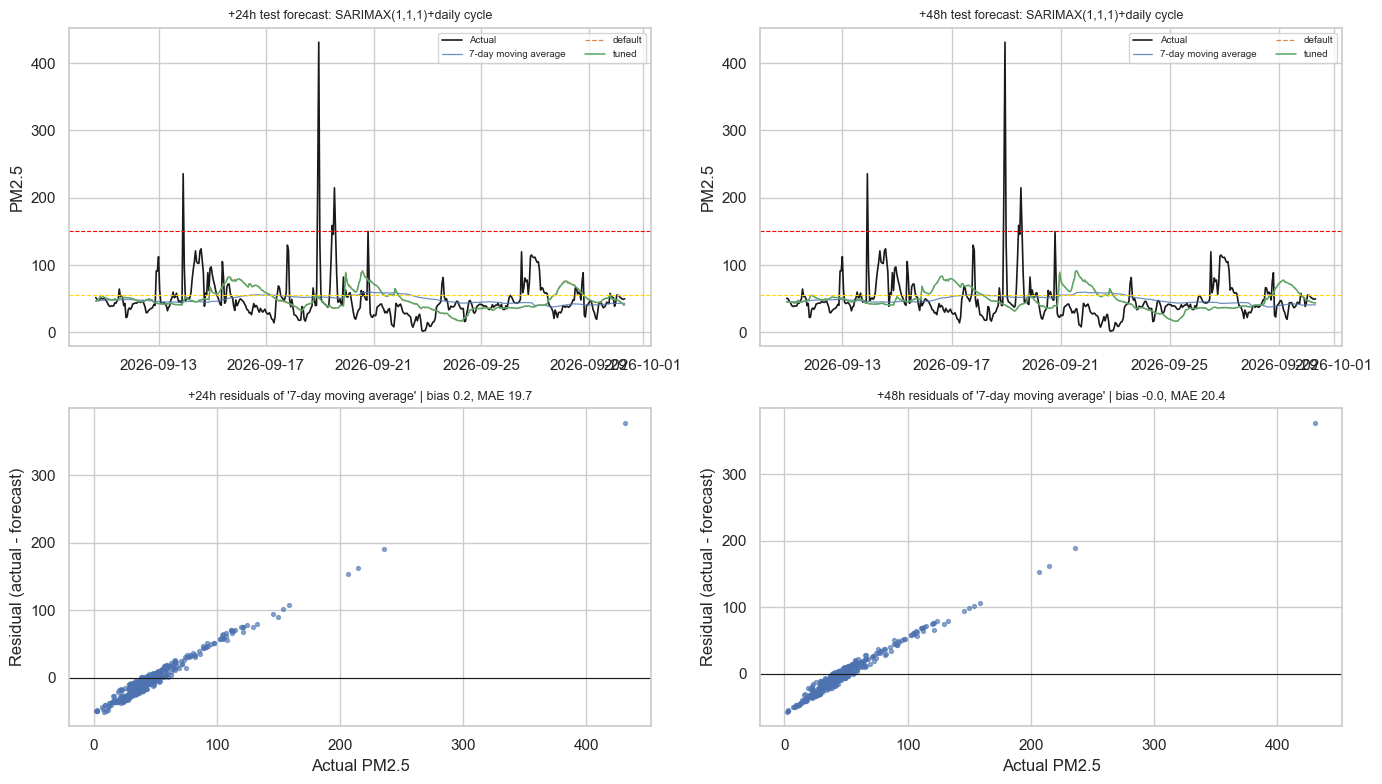

In [140]:
fam_best = best_model
fig, axes = plt.subplots(2, len(HORIZONS), figsize=(14, 8))
for j, h in enumerate(HORIZONS):
    te = split_idx(h, "test"); yt = actual(h, te); tt = te + h * H
    pick = test_preds[h][FINAL if FINAL in BASELINES else f"{FINAL} [tuned]"]
    ax = axes[0][j]
    ax.plot(tt, yt.values, "k", lw=1.2, label="Actual")
    ax.plot(tt, test_preds[h][best_base].values, lw=0.9, alpha=0.8, label=best_base)
    ax.plot(tt, test_preds[h][f"{fam_best} [default]"].values, lw=0.9, ls="--", label="default")
    ax.plot(tt, test_preds[h][f"{fam_best} [tuned]"].values, lw=1.1, label="tuned")
    ax.axhline(EVENT_THR, color="gold", ls="--", lw=0.8); ax.axhline(HIGH_THR, color="red", ls="--", lw=0.8)
    ax.set_title(f"+{h}h test forecast: {fam_best[:28]}", fontsize=9); ax.set_ylabel("PM2.5"); ax.legend(fontsize=7, ncol=2)
    r = yt - pick
    ax2 = axes[1][j]; ax2.scatter(yt.values, r.values, s=8, alpha=0.6); ax2.axhline(0, color="k", lw=0.8)
    ax2.set_xlabel("Actual PM2.5"); ax2.set_ylabel("Residual (actual - forecast)")
    ax2.set_title(f"+{h}h residuals of '{FINAL[:24]}' | bias {r.mean():.1f}, MAE {r.abs().mean():.1f}", fontsize=9)
    ev = yt > EVENT_THR
    print(f"+{h}h mean residual when actual > {EVENT_THR}: {r[ev].mean():.1f} (n={int(ev.sum())}); otherwise {r[~ev].mean():.1f}")
plt.tight_layout(); plt.show()

## Part 4 · 10. Haze-event alerts (test set)
NEA cares about warnings, not only RMSE. A forecast above the threshold counts as an alert (no threshold tuning), first at 55 µg/m³ (the "Elevated" edge used as the haze-event definition) and then at 150 µg/m³ ("High"). A **false negative** is a missed haze event (the public is not warned); a **false positive** is an unnecessary alert. Check `actual_events`: with so few real events, precision and recall are only indicative.

In [141]:
def alert_table(thr):
    rows = []
    for h in HORIZONS:
        te = split_idx(h, "test"); truth = actual(h, te) > thr
        for mname, p in test_preds[h].items():
            pr = p > thr
            tp, fp, fn = int((pr & truth).sum()), int((pr & ~truth).sum()), int((~pr & truth).sum())
            rows.append({"horizon": f"+{h}h", "model": mname, "actual_events": int(truth.sum()), "TP": tp, "FP": fp, "FN": fn,
                         "precision": round(tp / (tp + fp), 2) if tp + fp else np.nan,
                         "recall": round(tp / (tp + fn), 2) if tp + fn else np.nan})
    return pd.DataFrame(rows).set_index(["horizon", "model"])
for thr in (EVENT_THR, HIGH_THR):
    print(f"Test-set alerts at PM2.5 > {thr} µg/m³"); display(alert_table(thr))

Test-set alerts at PM2.5 > 55 µg/m³


actual_events  TP   FP   FN  precision  recall
horizon model                                                                               
+24h    Naive (y_t)                                     102  20   87   82       0.19    0.20
        24h moving average                              102  27   92   75       0.23    0.26
        7-day moving average                            102   6   77   96       0.07    0.06
        SARIMAX(1,1,1)+daily cycle [default]            102  29   98   73       0.23    0.28
        SARIMAX(1,1,1)+daily cycle [tuned]              102  29  101   73       0.22    0.28
        Ridge (scale-free) [default]                    102  12   58   90       0.17    0.12
        Ridge (scale-free) [tuned]                      102  17   67   85       0.20    0.17
+48h    Naive (y_t)                                     102  20   81   82       0.20    0.20
        24h moving average                              102   9  110   93       0.08    0.09
        7-day moving average                            102   7   76   95       0.08    0.07
        SARIMAX(1,1,1)+daily cycle [default]            102  10  116   92       0.08    0.10
        SARIMAX(1,1,1)+daily cycle [tuned]              102  10  116   92       0.08    0.10
        Ridge (scale-free) [default]                    102   2   46  100       0.04    0.02
        Ridge (scale-free) [tuned]                      102  11   97   91       0.10    0.11

Test-set alerts at PM2.5 > 150 µg/m³


actual_events  TP  FP  FN  precision  recall
horizon model                                                                             
+24h    Naive (y_t)                                       6   0   6   6        0.0     0.0
        24h moving average                                6   0   0   6        NaN     0.0
        7-day moving average                              6   0   0   6        NaN     0.0
        SARIMAX(1,1,1)+daily cycle [default]              6   0   0   6        NaN     0.0
        SARIMAX(1,1,1)+daily cycle [tuned]                6   0   0   6        NaN     0.0
        Ridge (scale-free) [default]                      6   0   0   6        NaN     0.0
        Ridge (scale-free) [tuned]                        6   0   0   6        NaN     0.0
+48h    Naive (y_t)                                       6   0   6   6        0.0     0.0
        24h moving average                                6   0   0   6        NaN     0.0
        7-day moving average                              6   0   0   6        NaN     0.0
        SARIMAX(1,1,1)+daily cycle [default]              6   0   0   6        NaN     0.0
        SARIMAX(1,1,1)+daily cycle [tuned]                6   0   0   6        NaN     0.0
        Ridge (scale-free) [default]                      6   0   0   6        NaN     0.0
        Ridge (scale-free) [tuned]                        6   0   1   6        0.0     0.0

## Reading these results (Phase 5)

**Tuning outcome**
- **SARIMAX:** tuning changed CV RMSE by 0.02% (+24h) and 0.00% (+48h). The model is insensitive to its order and harmonics on this data, so the initial configuration was already adequate.
- **Ridge:** CV gains of 3.0% (+24h) and 5.5% (+48h) did not carry over to the test set. +24h improved slightly (35.70 to 35.25), but +48h got worse (36.53 to 37.97). The CV-best settings at +48h (`alpha=1`) were fitted to the validation-period regime, which is the "winner's curse" of picking the best of 64 candidates. Both horizons chose `half_life=336 h`, which suggests recent data should be weighted more because the series shifts from calm to hazy.
- All 95% test intervals overlap (roughly 23-49 µg/m³), so **none of these differences is statistically reliable**.

**Final selection**
The pre-declared rule (a tuned model must beat the best baseline by at least 5% in CV) was not met: the best tuned model (SARIMAX, mean CV RMSE 13.69) is 2% *worse* than the 7-day moving average (13.38). The test set confirms this (33.84 / 34.43 vs 35.25-38.64). **The 7-day moving average is therefore the recommended operational forecaster**: it needs no training, cannot overfit, and is simple to explain and audit. This is consistent with the project brief, which states that a simpler model may remain preferable.

**Alerts**
No model forecasts any of the 6 hours above 150 µg/m³ (recall 0.0 for all), so none can serve as a spike early-warning system. The naive forecast produces false alarms because it repeats a spike one day late.

**Caution on comparing CV and test**
CV RMSE (about 14) is much lower than test RMSE (about 35) because the folds end in early September, before the hazier late-September period. They measure different regimes and should not be compared directly.

## Part 4 · 11. Save tuning results
Saves the best parameters and result tables, so the report can quote the exact values and Part 5 (interpretation) can reuse them.

In [142]:
best_json = {f"{name} | +{h}h": p for (name, h), p in best.items()}
with open("tuning_best_params.json", "w") as f:
    json.dump(best_json, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
test_res.to_csv("test_results_final.csv", index=False)
summary.drop(columns="best_params").to_csv("tuning_summary.csv", index=False)
print("Recommended forecaster:", FINAL)
print(json.dumps(best_json, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

Recommended forecaster: 7-day moving average
{
  "SARIMAX(1,1,1)+daily cycle | +24h": {
    "K": 1,
    "p": 2,
    "q": 1
  },
  "SARIMAX(1,1,1)+daily cycle | +48h": {
    "K": 1,
    "p": 1,
    "q": 1
  },
  "Ridge (scale-free) | +24h": {
    "alpha": 10,
    "features": "scale-free + weather",
    "half_life": 336
  },
  "Ridge (scale-free) | +48h": {
    "alpha": 1,
    "features": "scale-free",
    "half_life": 336
  }
}


## Part 5 · 1. Interpreting the tuned Ridge model (+24h)
**Why Ridge and not the final baseline:** a moving average has no parameters to interpret, so we interpret the best learned model to see which signals carry information, and to understand why it still cannot beat the baseline.
- **Standardized coefficients:** features are scaled to mean 0, SD 1 inside the pipeline, so each coefficient is the change in the log-ratio target (log of PM2.5 at t+24h over PM2.5 now) for a +1 SD change in that feature. They are directly comparable in size.
- **Permutation importance (validation rows):** shuffling one feature and measuring the increase in RMSE shows how much the model *relies* on it, in µg/m³. Model fitted on training rows only; test untouched.
- **Both describe the model, not the world.** Features are correlated (for example, the 24 h and 7-day ratios), so importance is shared between them, and nothing here shows that a feature *causes* haze.

Tuned Ridge +24h: {'alpha': 10, 'features': 'scale-free + weather', 'half_life': 336}


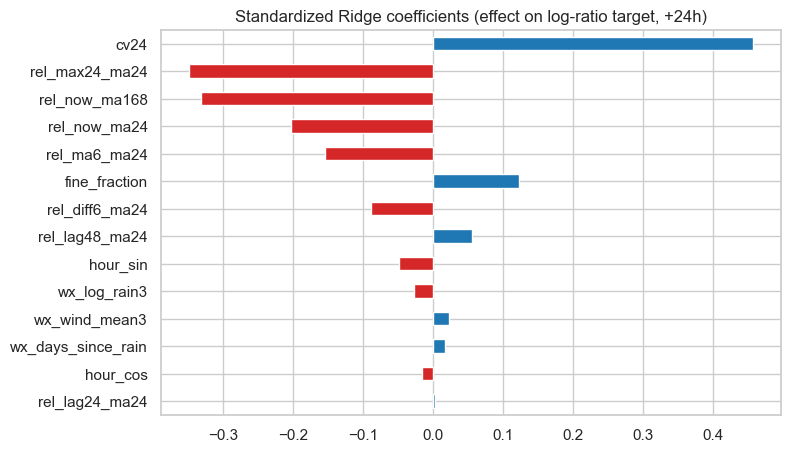

Validation RMSE of this model: 16.63


,rmse_increase,sd
feature,,
rel_now_ma168,2.10,0.30
cv24,1.66,0.26
fine_fraction,1.54,1.17
rel_max24_ma24,0.74,0.10
hour_sin,0.37,0.08
rel_now_ma24,0.29,0.14
rel_ma6_ma24,0.14,0.17
hour_cos,0.04,0.03
rel_diff6_ma24,0.03,0.04


In [143]:
h = 24
rname = [m for m in TOP2 if family(m) == "ridge"][0]
p = best[(rname, h)]
tr_ix, va_ix = split_idx(h, "train"), split_idx(h, "val")
pred_va, est = ridge_predict(p, h, tr_ix, va_ix)
X = FEATSETS[p["features"]]; cols = list(X.columns)
print("Tuned Ridge +24h:", p)

coef = pd.Series(est.named_steps["ridge"].coef_, index=cols).sort_values(key=abs)
coef.plot.barh(figsize=(8, 5), color=["tab:red" if v < 0 else "tab:blue" for v in coef])
plt.title("Standardized Ridge coefficients (effect on log-ratio target, +24h)"); plt.show()

yt, now_ev = actual(h, va_ix), data.loc[va_ix, "pm25_now"]
base_rmse = rmse(yt, pred_va)
rng = np.random.default_rng(42); rows = []
for c in cols:
    inc = []
    for _ in range(30):
        Xp = X.loc[va_ix].copy(); Xp[c] = rng.permutation(Xp[c].values)
        raw = pd.Series(est.predict(Xp), index=va_ix).clip(-1.5, 1.5)
        inc.append(rmse(yt, (now_ev * np.exp(raw)).clip(lower=0)) - base_rmse)
    rows.append({"feature": c, "rmse_increase": np.mean(inc), "sd": np.std(inc)})
perm = pd.DataFrame(rows).sort_values("rmse_increase", ascending=False)
print(f"Validation RMSE of this model: {base_rmse:.2f}")
display(perm.round(2).set_index("feature"))

### Reading the importance results (tuned Ridge, +24h)

**What the model relies on.** Validation RMSE of this model is 16.63 µg/m³. Shuffling a single feature raises RMSE most for:
- `rel_now_ma168` (+2.10 µg/m³): the current PM2.5 relative to its 7-day average. This is how unusual the current level is for the week, and it carries the same information as the 7-day moving-average baseline.
- `cv24` (+1.66): the 24 h variability relative to the 24 h mean. Unsettled air over the past day is informative.
- `fine_fraction` (+1.54, SD 1.17): the PM1/PM2.5 ratio. It might separate smoke-like from coarse particles, but its large SD means the importance is **unstable** and should be treated with caution.
- `rel_max24_ma24` (+0.74): the recent peak relative to the day's average.
- `hour_sin` (+0.37): the daily cycle.

All effects are modest (the largest is about 13% of the RMSE), so no single feature carries the forecast.

**What the model does not use.** The three daily-weather features (3-day rain, 3-day mean wind, days since rain) have slightly *negative* importance (-0.03 to -0.16 µg/m³): shuffling them does not hurt, so they add no predictive information here. This agrees with the Part 3 ablation. We interpret this narrowly: **one-day-old daily rain and wind totals from a single station, without wind direction, do not improve a 24 h forecast on this data.** It does not show that weather is irrelevant to haze.

**How to read this.** Importance describes what *this model* uses, not what causes haze. Several features are correlated (the level and peak ratios overlap), so importance is shared between them and each is probably understated. Importance was measured on validation rows, a single hazy period, so it may differ under other conditions.

## Part 5 · 2. Signed coefficients of the tuned Ridge model (+24h)
**Why this table:** permutation importance (5 · 1) shows how much the model *relies* on each feature, but not in which direction. The signed standardized coefficients show the direction. The target is the log of the ratio PM2.5(t+24h) / PM2.5(t), so a negative coefficient means "forecast a lower future-to-now ratio", not "lower PM2.5". The table is sorted by absolute size so the largest effects come first.

In [145]:
display(coef.sort_values(key=abs, ascending=False).round(3).to_frame("std_coef"))

,std_coef
cv24,0.457
rel_max24_ma24,-0.348
rel_now_ma168,-0.332
rel_now_ma24,-0.202
rel_ma6_ma24,-0.155
fine_fraction,0.122
rel_diff6_ma24,-0.088
rel_lag48_ma24,0.057
hour_sin,-0.049
wx_log_rain3,-0.027


# Part 5 · 3. Findings and actionable insights

| # | Finding | Evidence | Actionable insight | Limitation |
|---|---|---|---|---|
| 1 | **A 7-day moving average is the most dependable forecaster; tuned models do not beat it.** | Mean CV RMSE: 7-day average 13.38 vs tuned SARIMAX 13.69 and Ridge 14.04 (the 5% margin rule was not met). Test RMSE: 33.84 (+24h) and 34.43 (+48h) vs 35.25-38.64 for all tuned or default models. | Use the 7-day average as the low-cost benchmark forecast of typical PM2.5 levels. Require any future model to beat it by at least 5% in rolling-origin validation before adoption. | All test intervals overlap (about 23-50 µg/m³), so the ranking is not statistically reliable. |
| 2 | **None of the models is usable as a haze alert.** | At >150 µg/m³ all models miss all 6 test hours (recall 0.0). At >55 µg/m³ (102 of 473 test hours) the best recall is 0.28 with precision 0.23 (SARIMAX, +24h), so about 77% of alerts are false. The 7-day average, the best on RMSE, has recall of only 0.06. | Do not use these forecasts to trigger public warnings or health advisories. Keep alert decisions on existing monitoring and use model output only as supplementary context. | Only 6 hours above 150 µg/m³, and 5 of them on one day, so spike metrics are anecdotal. |
| 3 | **The model pulls forecasts back toward the recent average, which is why it misses the start of a haze episode.** | Ridge coefficients: all four "current level relative to recent average or peak" features are negative (-0.16 to -0.35), while 24 h variability is the largest positive one (+0.46). Permutation importance is highest for `rel_now_ma168` (+2.1 µg/m³). | The missing information is *outside* the sensor series. Prioritise upwind fire-hotspot data and wind direction over more complex models. | Coefficients and importance describe associations learned by this model, not causes of haze. Correlated ratio features share weight. |
| 4 | **Daily rain and wind from one station added no predictive value.** | Permutation importance -0.03 to -0.16 µg/m³ and coefficients near zero (|coef| < 0.03). The Part 3 ablation changed RMSE by under 1 µg/m³ with the sign flipping between validation and test. | Do not invest in more daily-weather features of this kind. If weather is added, it should be hourly with wind direction. | This shows that day-old daily summaries from one station do not help, not that weather is irrelevant to haze. |
| 5 | **Tuning gains did not transfer to the test period.** | Ridge +48h improved 5.5% in CV but was 3.9% worse on test (36.53 to 37.97). SARIMAX tuning changed CV RMSE by 0.0%. | Judge future models on a rolling-origin backtest over several haze episodes, not a single validation window. | Train mean 20, validation 38 and test 49 µg/m³ (regime shift), so tuning on calm and moderate periods favours settings that fail in hazier ones. |

# Part 5 · 4. Recommendations

1. **Adopt the 7-day moving average as the baseline forecaster for routine situational awareness, and as the benchmark any model must beat.** It needs no training, cannot overfit, and is simple to explain, audit and run in a spreadsheet. Use it for typical-level planning only, never for alerts.
2. **Do not deploy any of these models as an automated haze early-warning.** Their best alert performance (recall 0.28, precision 0.23) would miss most events and issue mostly false alarms. Keep alert decisions on existing agency procedures.
3. **Invest in the missing inputs before more modelling:** satellite fire hotspots and upwind sensor data, hourly weather with wind direction, several stations, and the October haze season. Re-run this workflow with the same protocol and the same 5% benchmark rule.
4. **Pilot in shadow mode** during the next haze season: log the forecasts next to actual values without acting on them, to check performance before any decision relies on it.

# Part 5 · 5. Business implications

- **Expected use:** a simple, transparent benchmark and a documented evaluation protocol for NEA analysts, not a decision-making tool for the public.
- **Implementation:** the benchmark needs only a rolling 7-day mean of hourly PM2.5, so there are no model maintenance or retraining costs. The main cost is data engineering for the upwind inputs in recommendation 3.
- **Risk to manage:** a 7-day average can give false reassurance because it reacts slowly. It looked best on RMSE yet detected only 6% of elevated hours, so it must not be presented as an alert.
- **Next steps:** extend the data to the October haze peak and multiple stations, add hotspot and wind-direction features, evaluate with a rolling-origin backtest over several episodes, and run the shadow-mode pilot.

**Limitations (summary):** a single low-cost, uncalibrated sensor; data only for April-September 2026; 6 hours above 150 µg/m³; a strong regime shift between training and test; a design choice (the scale-free variant) made after seeing validation behaviour; and results that are associations, not causal claims.